# Original-chip crosstalk — 729 and 830 nm, one driven channel each

Analyze `Gen1_OG_take_FINAL/729_nm_crosstalk` and `830_nm_crosstalk` independently. Each wavelength has **one driven optical channel**, its own focused reference, and its own manual alignment. Wavelengths are separate acquisitions; there is no cross-wavelength drive/response matrix.

Use the same longest-valid-exposure HDR rule as the Ca notebook: dark-corrected **R+G+B counts / actual exposure seconds**, minimum corrected signal, and per-RGB-channel saturation threshold. No exposure is excluded by default. “One channel” describes the driven device channel; TIFF RGB color channels are still summed.

Figures include HDR images, axial cuts, exposure maps/audits, peak rate versus height, crosstalk at both ±5 µm offsets, a **sampled-position matrix** (one column per wavelength, rows −5/0/+5 µm), reference axial profiles, four height–radial crosstalk maps, peak tracking, and exposure consistency. All spatial crosstalk sampling uses nearest valid measured pixels without interpolation. Invalid sampled pixels remain missing.

Run the function cells, settings, discovery, and manual alignment in order. A new wavelength requests two point pairs: lens angle, then coordinate origin. Saved alignments are reused afterward. Outputs and caches have their own paths; `cross_talk_analysis_ca_2.ipynb` is unchanged.

## Functions: discovery, dark calibration, and independent alignment

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from scipy import ndimage
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "Analysis/gate_image_profiler.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from Analysis.gate_image_profiler import GateImageProfiler


def discover_dataset(folder):
    """Find this dataset's latest complete run and its own preceding reference."""
    folder = Path(folder)
    timestamp = lambda s: datetime.fromisoformat(s.replace("Z", "+00:00"))
    runs = []
    for path in sorted(folder.glob("signal_*/run_metadata.json")):
        metadata = json.loads(path.read_text())
        if metadata.get("status") == "complete" and (path.parent / "exposure_log.csv").is_file():
            runs.append((timestamp(metadata["started_utc"]), path.parent, metadata))
    if not runs:
        raise FileNotFoundError(f"No complete signal run in {folder}")
    started, run_dir, metadata = max(runs, key=lambda item: item[0])
    references = []
    for path in sorted(folder.glob("focused_*.json")):
        ref = json.loads(path.read_text())
        if ref.get("capture_kind") != "focused":
            continue
        image_path = folder / ref["raw_tiff"]
        received = timestamp(ref["frame_received_utc"])
        if image_path.is_file() and received <= started:
            references.append((received, image_path, ref))
    if not references:
        raise FileNotFoundError(f"No focused reference preceding {run_dir.name}")
    _, reference_path, reference_metadata = max(references, key=lambda item: item[0])
    table = pd.read_csv(run_dir / "exposure_log.csv").sort_values(
        ["height_index", "time_index", "exposure_index", "frame_index"]
    ).reset_index(drop=True)
    table.index.name = "image_index"
    table["path"] = table.filename.map(lambda name: run_dir / name)
    if len(table) != metadata["planned_frames"] or not len(table):
        raise ValueError(f"Incomplete exposure log: {run_dir}")
    missing = [str(p) for p in table.path if not p.is_file()]
    if missing:
        raise FileNotFoundError(f"Missing {len(missing)} frames, including {missing[0]}")
    return dict(name=folder.name, folder=folder, run_dir=run_dir, metadata=metadata,
                reference_path=reference_path, reference_metadata=reference_metadata,
                frames=table)


def load_dark_calibration(path):
    """The calibration is ONE spatial mean of R+G+B per exposure, not three means."""
    path = Path(path)
    with np.load(path, allow_pickle=False) as data:
        if data["exposure_unit"].item() != "ms":
            raise ValueError("Dark exposures must be in ms")
        if data["dark_count_definition"].item() != "mean over frames and pixels of B+G+R":
            raise ValueError("Unexpected dark-count units")
        exposure = data["actual_exposures_ms"].copy()
        counts = data["dark_counts"].copy()
        metadata = json.loads(data["metadata_json"].item())
    order = np.argsort(exposure)
    exposure, counts = exposure[order], counts[order]
    if (exposure.ndim != 1 or counts.shape != exposure.shape or len(exposure) < 2
            or not np.isfinite(exposure).all() or not np.isfinite(counts).all()
            or np.any(np.diff(exposure) <= 0)):
        raise ValueError("Invalid dark calibration exposure grid")
    return dict(path=path, exposure_ms=exposure, counts=counts, metadata=metadata)


def dark_at(dark, exposure_ms):
    exposure_ms = np.asarray(exposure_ms, dtype=float)
    grid = dark["exposure_ms"]
    if (not np.isfinite(exposure_ms).all() or np.any(exposure_ms < grid[0])
            or np.any(exposure_ms > grid[-1])):
        raise ValueError(f"Exposure outside dark calibration range [{grid[0]}, {grid[-1]}] ms")
    return np.interp(exposure_ms, grid, dark["counts"])


def rotate_pixels(image, angle_deg):
    """Rotate about image center and crop to the same shape; empty corners are zero."""
    return ndimage.rotate(image, float(angle_deg), axes=(1, 0), reshape=False,
                          order=0, mode="constant", cval=0, prefilter=False)


def reference_signature(dataset):
    path = dataset["reference_path"]
    return dict(reference_name=path.name, reference_size=path.stat().st_size,
                reference_mtime_ns=path.stat().st_mtime_ns)


def save_alignment(dataset, record, directory):
    """Save only this dataset's alignment; no cross-dataset registration is used."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    record = dict(record, **reference_signature(dataset))
    (directory / f"{dataset['name']}.json").write_text(json.dumps(record, indent=2) + "\n")
    return record


def load_alignment(dataset, directory):
    path = Path(directory) / f"{dataset['name']}.json"
    if not path.is_file():
        return None
    record = json.loads(path.read_text())
    if any(record.get(key) != value for key, value in reference_signature(dataset).items()):
        return None
    return record


def select_alignment(dataset, directory, *, pixel_pitch_um=(5.3, 5.3), magnification=50.0):
    """Two point pairs on this dataset's own reference: angle, then origin."""
    print(f"Aligning {dataset['name']}: {dataset['reference_path'].name}", flush=True)
    profiler = GateImageProfiler(pixel_pitch_um=pixel_pitch_um, magnification=magnification,
        ion_relative_to_wg_lens_um=0, wg_lens_relative_to_trench_um=0, interpolation_order=0)
    alignment = profiler.align_white_light(dataset["reference_path"], brightness_offset=0,
                                          select_rois=False)
    return save_alignment(dataset, dict(angle_deg=alignment.angle_deg,
        origin_px=list(alignment.trench_center_px), pixel_pitch_um=list(pixel_pitch_um),
        magnification=float(magnification), method="independent manual selection",
        rotation_points_px=alignment.rotation_points_px.tolist(),
        origin_points_px=alignment.trench_edges_px.tolist()), directory)


def image_axes(shape, alignment):
    ny, nx = shape[:2]
    dx, dy = np.asarray(alignment["pixel_pitch_um"], dtype=float) / alignment["magnification"]
    cx, cy = alignment["origin_px"]
    if not (0 <= cx < nx and 0 <= cy < ny and dx > 0 and dy > 0):
        raise ValueError("Invalid alignment origin or sample spacing")
    x, y = (np.arange(nx) - cx) * dx, (np.arange(ny) - cy) * dy
    extent = (x[0]-dx/2, x[-1]+dx/2, y[-1]+dy/2, y[0]-dy/2)
    return x, y, extent


def preview_references(datasets, alignments):
    fig, axes = plt.subplots(1, len(datasets), figsize=(5*len(datasets), 4), constrained_layout=True)
    for ax, (ion, dataset) in zip(np.atleast_1d(axes), datasets.items()):
        if ion not in alignments:
            ax.text(.5, .5, f"{dataset['name']}\nAlignment still needed", ha="center", transform=ax.transAxes)
            continue
        a = alignments[ion]
        image = rotate_pixels(tifffile.imread(dataset["reference_path"]), a["angle_deg"])
        _, _, extent = image_axes(image.shape, a)
        ax.imshow(image, origin="upper", extent=extent)
        ax.axhline(0, color="cyan", lw=.7)
        ax.axvline(0, color="cyan", lw=.7)
        ax.set(title=f"{dataset['name']}\nrotation = {a['angle_deg']:.4f} deg",
               xlabel="Axial x (um)", ylabel="Radial y (um)")
    plt.show()
    plt.close(fig)


## Functions: longest-valid HDR and peak-row extraction

In [2]:
def _fingerprint(dataset, alignment, dark, min_signal, max_rgb, excluded_exposures_ms=()):
    files = [dataset["run_dir"] / "exposure_log.csv", dark["path"], *dataset["frames"].path]
    payload = dict(version=2, hdr_selection="longest_valid_exposure", alignment=alignment, min_signal=float(min_signal), max_rgb=float(max_rgb),
                   files=[(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in files])
    excluded = sorted(set(map(float, excluded_exposures_ms)))
    if excluded:
        payload["excluded_requested_exposure_ms"] = excluded
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()



def process_dataset(dataset, alignment, dark, *, min_signal=5, max_rgb=220, cache_dir=None,
                    excluded_exposures_ms=()):
    """Use the longest valid exposure per pixel; report dark-corrected RGB counts/s."""
    if not np.isfinite(min_signal) or min_signal < 0 or not 0 < max_rgb <= 255:
        raise ValueError("Require min_signal >= 0 and 0 < max_rgb <= 255")
    for key in ("camera_id", "pixel_clock_mhz", "width", "height", "pixel_format"):
        if dark["metadata"][key] != dataset["metadata"][key]:
            raise ValueError(f"Dark calibration mismatch for {dataset['name']}: {key}")
    frames = dataset["frames"]
    excluded = np.asarray(excluded_exposures_ms, dtype=float)
    if excluded.ndim != 1 or not np.isfinite(excluded).all() or np.any(excluded <= 0):
        raise ValueError("Excluded nominal exposure times must be a finite positive list")
    excluded = sorted(set(excluded.tolist()))
    include_frame = np.ones(len(frames), dtype=bool)
    for exposure in excluded:
        include_frame &= ~np.isclose(frames.requested_exposure_ms, exposure, rtol=0, atol=1e-6)
    seconds = frames.actual_exposure_ms.to_numpy(dtype=float) / 1000
    if not np.isfinite(seconds).all() or np.any(seconds <= 0):
        raise ValueError("Actual exposure times must be positive and finite")
    dark_levels = dark_at(dark, frames.actual_exposure_ms)
    reference = rotate_pixels(tifffile.imread(dataset["reference_path"]), alignment["angle_deg"])
    x, y, extent = image_axes(reference.shape, alignment)
    reference_corrected = reference.sum(axis=-1, dtype=np.uint16).astype(np.float32)
    reference_corrected -= float(dark_at(dark, dataset["reference_metadata"]["exposure_ms"]))
    np.maximum(reference_corrected, 0, out=reference_corrected)
    fingerprint = _fingerprint(dataset, alignment, dark, min_signal, max_rgb, excluded)
    base = dict(dataset=dataset, alignment=alignment, x_um=x, y_um=y, extent=extent,
                reference_corrected=reference_corrected, min_signal=min_signal, max_rgb=max_rgb,
                excluded_exposures_ms=excluded, hdr_selection="longest_valid_exposure")
    cache_path = None if cache_dir is None else Path(cache_dir) / f"{dataset['name']}.npz"
    if cache_path is not None and cache_path.is_file():
        with np.load(cache_path, allow_pickle=False) as cached:
            if cached["fingerprint"].item() == fingerprint:
                info = json.loads(cached["tables_json"].item())
                base.update(rate=cached["rate"].copy(), source=cached["source"].copy(),
                            heights_um=cached["heights_um"].copy())
                for key, records in info.items():
                    base[key] = pd.DataFrame(records)
                print(f"{dataset['name']}: reused processed cache", flush=True)
                return base
    groups = list(frames.groupby("height_index", sort=True).indices.items())
    shape = (len(groups), *reference.shape[:2])
    rate = np.zeros(shape, dtype=np.float32)
    source_dtype = np.int16 if len(frames) < 32767 else np.int32
    source = np.full(shape, -1, dtype=source_dtype)
    heights, summary, saturation, comparisons = [], [], [], []
    for slot, (height_id, indices) in enumerate(groups):
        indices = np.asarray(indices)
        physical_heights = frames.iloc[indices].target_height_um.to_numpy()
        if not np.allclose(physical_heights, physical_heights[0], rtol=0, atol=1e-5):
            raise ValueError("Inconsistent heights within an exposure group")
        height = float(physical_heights[0])
        heights.append(height)
        indices = indices[include_frame[indices]]
        if not len(indices):
            raise ValueError(f"All exposures excluded at height {height:g} um")
        candidates = []
        for index in indices[np.argsort(seconds[indices], kind="stable")]:
            raw = tifffile.imread(frames.iloc[index].path)
            if raw.shape != reference.shape or raw.dtype != np.uint8:
                raise ValueError(f"Unexpected RGB shape/dtype in {frames.iloc[index].path}")
            if np.isclose(frames.iloc[index].requested_exposure_ms, .2, rtol=0, atol=1e-6):
                maxima = raw.max(axis=(0, 1))
                saturation.append(dict(height_index=int(height_id), height_um=height,
                    max_R=int(maxima[0]), max_G=int(maxima[1]), max_B=int(maxima[2]),
                    saturated_pixels=int(np.count_nonzero(np.any(raw >= 255, axis=-1))),
                    all_channels_below_sat=bool((maxima < 255).all())))
            rgb = rotate_pixels(raw, alignment["angle_deg"])
            corrected = rgb.sum(axis=-1, dtype=np.uint16).astype(np.float32)
            corrected -= np.float32(dark_levels[index])
            np.maximum(corrected, 0, out=corrected)
            channel_peak = rgb.max(axis=-1)
            candidate_rate = corrected / seconds[index]
            valid = (corrected > min_signal) & (channel_peak < max_rgb) & np.isfinite(candidate_rate)
            # Frames are ordered shortest to longest; every valid longer frame replaces the prior source.
            take = valid
            rate[slot, take] = candidate_rate[take]
            source[slot, take] = index
            candidates.append((int(index), corrected, channel_peak))
        valid = source[slot] >= 0
        record = dict(height_index=int(height_id), height_um=height,
            valid_pixels_pct=float(100*valid.mean()), peak_x_um=np.nan, peak_y_um=np.nan,
            peak_rate_counts_s=np.nan, peak_exposure_ms=np.nan,
            peak_requested_exposure_ms=np.nan, peak_uses_0p2_ms=False)
        if valid.any():
            row, col = np.unravel_index(np.argmax(rate[slot]), rate[slot].shape)
            chosen = int(source[slot, row, col])
            nominal = float(frames.iloc[chosen].requested_exposure_ms)
            record.update(peak_x_um=float(x[col]), peak_y_um=float(y[row]),
                peak_rate_counts_s=float(rate[slot, row, col]),
                peak_exposure_ms=float(seconds[chosen]*1000), peak_requested_exposure_ms=nominal,
                peak_uses_0p2_ms=bool(np.isclose(nominal, .2, rtol=0, atol=1e-6)))
            for index, counts_image, channel_image in candidates:
                counts, channel = float(counts_image[row, col]), int(channel_image[row, col])
                comparisons.append(dict(height_index=int(height_id), height_um=height,
                    requested_exposure_ms=float(frames.iloc[index].requested_exposure_ms),
                    actual_exposure_ms=float(seconds[index]*1000), corrected_counts=counts,
                    max_rgb_channel=channel, rate_counts_s=counts/seconds[index],
                    passes_thresholds=bool(counts > min_signal and channel < max_rgb),
                    selected_at_peak=bool(index == chosen)))
        summary.append(record)
        del candidates
        if slot == 0 or (slot+1) % 5 == 0 or slot+1 == len(groups):
            print(f"{dataset['name']}: {slot+1}/{len(groups)} heights", flush=True)
    base.update(rate=rate, source=source, heights_um=np.asarray(heights),
                summary=pd.DataFrame(summary), saturation=pd.DataFrame(saturation),
                comparisons=pd.DataFrame(comparisons))
    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        info = {key: json.loads(base[key].to_json(orient="records"))
                for key in ("summary", "saturation", "comparisons")}
        np.savez_compressed(cache_path, fingerprint=fingerprint, rate=rate, source=source,
                           heights_um=base["heights_um"], tables_json=json.dumps(info))
    return base



def height_slot(result, height_um, tolerance=1e-4):
    matches = np.flatnonzero(np.isclose(result["heights_um"], height_um, rtol=0, atol=tolerance))
    if len(matches) != 1:
        raise ValueError(f"Height {height_um:g} um not uniquely available in {result['dataset']['name']}")
    return int(matches[0])



def axial_profile(result, slot, y_um=None):
    """Use the brightest-pixel row or the nearest measured row to a requested y."""
    image = result["rate"][slot]
    valid = (result["source"][slot] >= 0) & np.isfinite(image) & (image > 0)
    x, y = result["x_um"], result["y_um"]
    if y_um is None:
        if not valid.any():
            return np.full(len(x), np.nan), np.nan, np.nan, np.nan
        row, _ = np.unravel_index(np.argmax(np.where(valid, image, -np.inf)), image.shape)
        profile = np.where(valid[row], image[row], np.nan)
        selected_y = float(y[row])
    else:
        if not np.isfinite(y_um) or not y[0] <= y_um <= y[-1]:
            raise ValueError(f"Requested y={y_um} outside {result['dataset']['name']} image")
        row = int(np.argmin(np.abs(y-y_um)))
        profile = np.where(valid[row], image[row], np.nan)
        selected_y = float(y[row])
    if not np.isfinite(profile).any():
        return profile, np.nan, selected_y, np.nan
    col = int(np.nanargmax(profile))
    return profile, float(x[col]), selected_y, float(profile[col])



def ratio_db(value, reference):
    return float(10*np.log10(value/reference)) if (np.isfinite(value) and value > 0
        and np.isfinite(reference) and reference > 0) else np.nan



## Functions: HDR images and exposure diagnostics

In [3]:
def plot_hdr(result, heights_um, db_floor=-40, y_um=None):
    """Display an axial cut at the nearest measured y; None follows the brightest row."""
    frames = result["dataset"]["frames"]
    nominal = frames.requested_exposure_ms.to_numpy()
    from matplotlib.colors import ListedColormap
    all_levels = np.sort(np.unique(nominal))
    excluded = result.get("excluded_exposures_ms", [])
    eligible = np.ones(len(all_levels), dtype=bool)
    for exposure in excluded:
        eligible &= ~np.isclose(all_levels, exposure, rtol=0, atol=1e-6)
    levels = all_levels[eligible]
    if not len(levels):
        raise ValueError("No eligible exposure levels to plot")
    # Preserve the original exposure colors across ions, while hiding excluded levels.
    base_colors = plt.get_cmap("viridis", len(all_levels))(np.arange(len(all_levels)))
    exposure_cmap = ListedColormap(base_colors[eligible])
    exposure_cmap.set_bad("lightgray")
    norm = BoundaryNorm(np.arange(len(levels)+1)-.5, len(levels))
    cmap = plt.get_cmap("inferno").copy()
    cmap.set_bad("lightgray")
    heights_um = result["heights_um"] if heights_um is None else heights_um
    for height in heights_um:
        slot = height_slot(result, height)
        profile, px, py, peak = axial_profile(result, slot, y_um=y_um)
        if not np.isfinite(peak):
            continue
        valid = result["source"][slot] >= 0
        image = np.full(valid.shape, np.nan, dtype=np.float32)
        # Keep the full image normalized to its global peak when selecting a weaker row.
        image_peak = float(np.max(result["rate"][slot, valid]))
        image[valid] = 10*np.log10(result["rate"][slot, valid]/image_peak)
        category = np.zeros(valid.shape, dtype=np.int16)
        category[valid] = np.searchsorted(levels, nominal[result["source"][slot, valid]])
        fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
        fig.suptitle(f"{result['dataset']['name']} | height = {height:g} um")
        im = axes[0].imshow(image, origin="upper", extent=result["extent"], cmap=cmap,
                            vmin=db_floor, vmax=0, interpolation="nearest")
        axes[0].plot(px, py, "+", color="cyan")
        axes[0].axhline(py, color="cyan", ls="--", lw=.7)
        axes[0].set(title="HDR rate", xlabel="Axial x (um)", ylabel="Radial y (um)")
        fig.colorbar(im, ax=axes[0], label="Intensity / image peak (dB)")
        axes[1].plot(result["x_um"], 10*np.log10(profile/peak), lw=1)
        axes[1].plot(px, 0, "ro", ms=4)
        row_title = f"Axial row at y={py:.3f} um"
        if y_um is not None:
            row_title += f" (requested {float(y_um):g})"
        axes[1].set(title=row_title, xlabel="Axial x (um)",
                    ylabel="Intensity / selected-row peak (dB)", ylim=(db_floor, 1))
        axes[1].grid(alpha=.3)
        im = axes[2].imshow(np.ma.array(category, mask=~valid), origin="upper",
            extent=result["extent"], cmap=exposure_cmap, norm=norm, interpolation="nearest")
        cb = fig.colorbar(im, ax=axes[2], ticks=np.arange(len(levels)))
        cb.set_ticklabels([f"{t:g}" for t in levels])
        cb.set_label("Selected exposure (ms; nominal)")
        axes[2].axhline(py, color="cyan", ls="--", lw=.7)
        axes[2].set(title="Exposure selection", xlabel="Axial x (um)", ylabel="Radial y (um)")
        plt.show()
        plt.close(fig)



def audit_hdr_exposure_selection(result, dark, height_um=75.0, y_um=14.0):
    """Verify current longest-valid HDR and compare with the former maximum-rate rule.

    Both strategies use the same dark subtraction, thresholds, rotation, and
    included frames. The far-field ROI is >20 um from the 2-D peak in BOTH
    coordinates, excluding rotated image corners and a 20-pixel border.
    """
    slot = height_slot(result, height_um)
    frames = result["dataset"]["frames"]
    x, y = result["x_um"], result["y_um"]
    current = result["rate"][slot]
    peak_row, peak_col = np.unravel_index(np.argmax(current), current.shape)
    row = peak_row if y_um is None else int(np.argmin(abs(y-float(y_um))))
    col = int(np.argmax(current[row]))
    points = {"2D peak": (peak_row, peak_col), "selected-row peak": (row, col)}
    for offset in (5.0, 25.0):
        target = x[col] + offset
        if x[0] <= target <= x[-1]:
            points[f"selected row, peak + {offset:g} um"] = (row, int(np.argmin(abs(x-target))))
    footprint = rotate_pixels(np.ones(current.shape, dtype=np.uint8), result["alignment"]["angle_deg"]) > 0
    roi = (abs(y[:, None]-y[peak_row]) > 20) & (abs(x[None, :]-x[peak_col]) > 20) & footprint
    roi[:20] = False; roi[-20:] = False; roi[:, :20] = False; roi[:, -20:] = False
    if not roi.any():
        raise ValueError("No pixels in the far-field diagnostic ROI")
    longest_source = np.full(current.shape, -1, dtype=result["source"].dtype)
    longest_rate = np.zeros(current.shape, dtype=np.float32)
    rebuilt_source = np.full_like(longest_source, -1)
    rebuilt_rate = np.zeros_like(longest_rate)
    candidates = frames.index[np.isclose(frames.target_height_um, height_um, rtol=0, atol=1e-4)]
    candidates = sorted(candidates, key=lambda i: frames.loc[i, "actual_exposure_ms"])
    pixel_rows, background = [], []
    for index in candidates:
        frame = frames.loc[index]
        nominal = float(frame.requested_exposure_ms)
        if any(np.isclose(nominal, value, rtol=0, atol=1e-6)
               for value in result["excluded_exposures_ms"]):
            continue
        actual = float(frame.actual_exposure_ms)
        rgb = rotate_pixels(tifffile.imread(frame.path), result["alignment"]["angle_deg"])
        raw = rgb.sum(axis=-1, dtype=np.uint16).astype(np.float32)
        dark_level = float(dark_at(dark, actual))
        corrected = np.maximum(raw-np.float32(dark_level), 0)
        rate = corrected/(actual/1000)
        channel = rgb.max(axis=-1)
        valid = (corrected > result["min_signal"]) & (channel < result["max_rgb"]) & np.isfinite(rate)
        take = valid & (rate > rebuilt_rate)
        rebuilt_rate[take], rebuilt_source[take] = rate[take], index
        # Ascending exposure order: overwrite every valid pixel with the longer exposure.
        longest_rate[valid], longest_source[valid] = rate[valid], index
        for point, (r, c) in points.items():
            pixel_rows.append(dict(point=point, x_um=x[c], y_um=y[r], exposure_ms=nominal,
                actual_exposure_ms=actual, raw_counts=float(raw[r, c]), dark_counts=dark_level,
                corrected_counts=float(corrected[r, c]), rate_counts_s=float(rate[r, c]),
                max_channel=int(channel[r, c]), valid=bool(valid[r, c]),
                selected_current=bool(result["source"][slot, r, c] == index)))
        background.append(dict(exposure_ms=nominal, actual_exposure_ms=actual,
            dark_counts=dark_level, raw_mean_counts=float(raw[roi].mean()),
            raw_mean_rate_counts_s=float(raw[roi].mean()/(actual/1000)),
            corrected_mean_rate_counts_s=float(rate[roi].mean()),
            valid_roi_percent=float(100*valid[roi].mean())))
    if not np.array_equal(longest_source, result["source"][slot]):
        raise RuntimeError("Rebuilt source map differs from cached HDR; rerun processing")
    np.testing.assert_allclose(longest_rate, current, rtol=1e-6, atol=1e-5)
    usage = []
    for label, source in (("Current: longest valid", longest_source),
                          ("Comparison: maximum rate", rebuilt_source)):
        for nominal in sorted(frames.loc[candidates, "requested_exposure_ms"].unique()):
            ids = frames.index[np.isclose(frames.requested_exposure_ms, nominal, rtol=0, atol=1e-6)]
            usage.append(dict(strategy=label, exposure_ms=nominal,
                              far_field_percent=float(100*np.isin(source[roi], ids).mean())))
    return dict(height_um=float(result["heights_um"][slot]), result=result, roi=roi,
                current_source=longest_source, longest_source=longest_source,
                maximum_rate_source=rebuilt_source, maximum_rate_rate=rebuilt_rate,
                longest_rate=longest_rate, pixels=pd.DataFrame(pixel_rows),
                background=pd.DataFrame(background), usage=pd.DataFrame(usage))



def plot_hdr_exposure_audit(audit):
    """Display diagnostics inline only; no figures are exported."""
    from matplotlib.colors import ListedColormap
    result = audit["result"]
    frames = result["dataset"]["frames"]
    levels = np.sort(audit["background"].exposure_ms.unique())
    cmap = ListedColormap(plt.get_cmap("tab10")(np.linspace(0, 1, len(levels))))
    cmap.set_bad("#cccccc")
    norm = BoundaryNorm(np.arange(len(levels)+1)-0.5, len(levels))
    with plt.rc_context({"font.family": "Arial", "font.size": 12}):
        fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
        for ax, key, title in zip(axes[:2], ("current_source", "maximum_rate_source"),
                ("Current: longest valid exposure", "Comparison: maximum counts/s")):
            source = audit[key]
            image = np.full(source.shape, np.nan)
            for category, exposure in enumerate(levels):
                ids = frames.index[np.isclose(frames.requested_exposure_ms, exposure, rtol=0, atol=1e-6)]
                image[np.isin(source, ids)] = category
            im = ax.imshow(np.ma.masked_invalid(image), extent=result["extent"], origin="upper",
                           cmap=cmap, norm=norm, interpolation="nearest")
            ax.set(title=title, xlabel="Axial x (um)", ylabel="Radial y (um)")
        cb = fig.colorbar(im, ax=axes[:2], ticks=np.arange(len(levels)), shrink=0.85)
        cb.ax.set_yticklabels([f"{v:g}" for v in levels])
        cb.set_label("Selected exposure (ms)")
        b = audit["background"]
        axes[2].loglog(b.exposure_ms, b.raw_mean_rate_counts_s, "o-", label="Before dark subtraction")
        axes[2].loglog(b.exposure_ms, b.corrected_mean_rate_counts_s, "s-", label="After dark subtraction")
        axes[2].set(title="Same far-field ROI at each exposure", xlabel="Exposure (ms)",
                    ylabel="Mean RGB counts / actual seconds")
        axes[2].grid(alpha=0.25); axes[2].legend(fontsize=9)
        fig.suptitle(f"{result['dataset']['name']} | height = {audit['height_um']:g} um")
        plt.show()
        plt.close(fig)



## Functions: reference windows and wavelength-labeled publication plots

In [4]:
def _sample_profile_grid(x, cube, valid, targets):
    """Use the closest measured axial pixel, preserving invalid samples."""
    inside = np.isfinite(targets) & (targets >= x[0]) & (targets <= x[-1])
    right = np.clip(np.searchsorted(x, targets), 0, len(x)-1)
    left = np.maximum(right-1, 0)
    nearest = np.where(np.abs(targets-x[left]) <= np.abs(x[right]-targets), left, right)
    take = lambda array: np.take_along_axis(array, nearest[..., None], axis=2)[..., 0]
    good = inside & take(valid)
    values = np.where(good & (take(cube) > 0), take(cube), np.nan)
    return values, nearest, nearest, np.zeros(targets.shape)



def sample_nearest(x, values, target):
    if not np.isfinite(target) or not x[0] <= target <= x[-1]:
        return np.nan, np.nan
    index = int(np.argmin(np.abs(x-target)))
    value = values[index]
    return (float(value), float(x[index])) if np.isfinite(value) and value > 0 else (np.nan, float(x[index]))



def _uniform_window(center, half_range, step):
    if not np.isfinite(step) or step <= 0:
        raise ValueError("Sampling steps must be finite and positive")
    intervals = 2*half_range/step
    if not np.isclose(intervals, round(intervals), rtol=0, atol=1e-9):
        raise ValueError("The full sampling window must be an integer multiple of its step")
    return center-half_range+np.arange(int(round(intervals))+1)*step



def analyze_reference_windows(results, offsets_by_wavelength, reference_height_um=75.,
                              height_half_range_um=10., radial_half_range_um=5.,
                              peak_search_half_width_um=None, radial_step_um=None,
                              height_step_um=None):
    """Use nearest measured heights, radial rows, and axial pixels; no interpolation.

    Nominal target coordinates and actual sampled coordinates are both recorded.
    None sampling steps preserve the corresponding native grid.
    """
    if set(results) != set(offsets_by_wavelength):
        raise ValueError("Specify signed neighbor offsets for every wavelength")
    if (not np.isfinite([reference_height_um, height_half_range_um, radial_half_range_um]).all()
            or height_half_range_um <= 0 or radial_half_range_um <= 0):
        raise ValueError("Reference height and positive finite window ranges are required")
    if peak_search_half_width_um is not None and (
            not np.isfinite(peak_search_half_width_um) or peak_search_half_width_um <= 0):
        raise ValueError("Optional axial peak-search half-width must be positive")
    maps, anchors, baseline_records = {}, [], []
    for wavelength_nm, result in sorted(results.items()):
        offsets = np.asarray(offsets_by_wavelength[wavelength_nm], dtype=float)
        if offsets.ndim != 1 or len(offsets) < 1 or not np.isfinite(offsets).all() or np.any(offsets == 0):
            raise ValueError("Each wavelength needs at least one finite nonzero axial offset")
        ref_slot = height_slot(result, reference_height_um)
        reference_profile, x0, y0, reference_peak = axial_profile(result, ref_slot)
        if not np.isfinite(reference_peak):
            raise ValueError(f"No valid reference peak at {wavelength_nm} nm")
        x, y, heights = result["x_um"], result["y_um"], result["heights_um"]
        if (heights.min() > reference_height_um-height_half_range_um+1e-4
                or heights.max() < reference_height_um+height_half_range_um-1e-4):
            raise ValueError(f"{wavelength_nm} nm: requested height window is not covered")
        if y0-radial_half_range_um < y[0] or y0+radial_half_range_um > y[-1]:
            raise ValueError(f"{wavelength_nm} nm: requested radial window extends outside the image")
        if height_step_um is None:
            h_indices = np.flatnonzero(np.abs(heights-reference_height_um) <= height_half_range_um+1e-4)
            h_indices = h_indices[np.argsort(heights[h_indices])]
        else:
            requested_heights = _uniform_window(reference_height_um, height_half_range_um, height_step_um)
            h_indices = np.asarray([int(np.argmin(np.abs(heights-h))) for h in requested_heights])
        if radial_step_um is None:
            lower = np.flatnonzero(np.abs(y-y0) <= radial_half_range_um+1e-10)
            upper, radial_y = lower.copy(), y[lower]
            radial_weight = np.zeros(len(lower))
        else:
            radial_y = _uniform_window(y0, radial_half_range_um, radial_step_um)
            lower = np.asarray([int(np.argmin(np.abs(y-target))) for target in radial_y])
            upper = lower.copy()
            radial_weight = np.zeros(len(radial_y))
        if len(h_indices) < 2 or len(radial_y) < 2:
            raise ValueError("At least two heights and radial coordinates are needed")
        cols = np.arange(len(x))
        # Directly take the selected measured rows: no blending or interpolation.
        cube = result["rate"][np.ix_(h_indices, lower, cols)]
        low_sources = result["source"][np.ix_(h_indices, lower, cols)]
        high_sources = low_sources  # Same selected pixel in both provenance slots.
        valid = (low_sources >= 0) & np.isfinite(cube) & (cube > 0)
        search = valid.copy()
        if peak_search_half_width_um is not None:
            search &= (np.abs(x-x0) <= peak_search_half_width_um)[None, None, :]
        found_peak = search.any(axis=2)
        peak_col = np.argmax(np.where(search, cube, -np.inf), axis=2)
        take = lambda array, index: np.take_along_axis(array, index[..., None], axis=2)[..., 0]
        central = np.where(found_peak, take(cube, peak_col), np.nan)
        peak_x = np.where(found_peak, x[peak_col], np.nan)
        peak_sources = np.stack([take(low_sources, peak_col), take(high_sources, peak_col)], axis=-1)
        peak_sources[~found_peak] = -1
        ratios, db_maps, numerator_maps, neighbor_sources, weights, sampled_x = [], [], [], [], [], []
        for offset in offsets:
            numerator, left, right, fraction = _sample_profile_grid(x, cube, valid, peak_x+offset)
            ratio = np.divide(numerator, central, out=np.full(central.shape, np.nan),
                              where=np.isfinite(central) & (central > 0))
            if peak_search_half_width_um is None and np.any(ratio[np.isfinite(ratio)] > 1+1e-6):
                raise AssertionError("Neighbor rate exceeds the full-slice maximum")
            positive = np.isfinite(ratio) & (ratio > 0)
            db = np.full(ratio.shape, np.nan)
            db[positive] = 10*np.log10(ratio[positive])
            # Provenance axes: [radial lower/upper, axial left/right].
            pairs = np.stack([
                np.stack([take(low_sources, left), take(low_sources, right)], axis=-1),
                np.stack([take(high_sources, left), take(high_sources, right)], axis=-1)], axis=-2)
            pairs[~positive] = -1
            ratios.append(ratio); db_maps.append(db); numerator_maps.append(numerator)
            neighbor_sources.append(pairs); weights.append(fraction)
            sampled_x.append(np.where(positive, x[left], np.nan))
        ref_row = int(np.argmin(np.abs(y-y0)))
        ref_col = int(np.argmin(np.abs(x-x0)))
        ref_source = int(result["source"][ref_slot, ref_row, ref_col])
        frames = result["dataset"]["frames"]
        anchors.append(dict(wavelength_nm=int(wavelength_nm), dataset=result["dataset"]["name"],
            reference_height_um=reference_height_um, peak_x_um=x0, peak_y_um=y0,
            reference_peak_counts_s=reference_peak,
            reference_exposure_ms=float(frames.iloc[ref_source].actual_exposure_ms),
            reference_nominal_exposure_ms=float(frames.iloc[ref_source].requested_exposure_ms),
            native_radial_step_um=float(np.median(np.diff(y))), radial_samples=len(radial_y),
            radial_sample_step_um=float(np.median(np.diff(radial_y))),
            height_sample_step_um=float(height_step_um if height_step_um is not None else np.median(np.diff(heights[h_indices])))))
        for offset in offsets:
            numerator, actual_x = sample_nearest(x, reference_profile, x0+offset)
            baseline_records.append(dict(wavelength_nm=int(wavelength_nm), offset_um=float(offset), height_um=reference_height_um,
                peak_x_um=x0, peak_y_um=y0, target_x_um=x0+offset, sample_x_um=actual_x,
                actual_offset_um=actual_x-x0, central_rate_counts_s=reference_peak,
                neighbor_rate_counts_s=numerator,
                crosstalk_linear=numerator/reference_peak if np.isfinite(numerator) else np.nan,
                crosstalk_db=ratio_db(numerator, reference_peak)))
        maps[wavelength_nm] = dict(wavelength_nm=int(wavelength_nm), offsets_um=offsets,
            heights_um=(heights[h_indices] if height_step_um is None else requested_heights),
            sampled_heights_um=heights[h_indices], sampled_radial_y_um=y[lower],
            sampled_neighbor_x_um=np.asarray(sampled_x),
            radial_y_um=radial_y, radial_offset_um=radial_y-y0,
            reference_x_um=x0, reference_y_um=y0, reference_height_um=reference_height_um,
            reference_profile=reference_profile, x_um=x, reference_peak_counts_s=reference_peak,
            central_rate=central, peak_x_um=peak_x, peak_sources=peak_sources,
            radial_interpolation_fraction=np.broadcast_to(radial_weight, central.shape).copy(),
            numerator_rate=np.asarray(numerator_maps), ratio=np.asarray(ratios), db=np.asarray(db_maps),
            neighbor_sources=np.asarray(neighbor_sources), interpolation_fraction=np.asarray(weights),
            frame_nominal_ms=frames.requested_exposure_ms.to_numpy(dtype=float),
            frame_actual_ms=frames.actual_exposure_ms.to_numpy(dtype=float))
    return dict(maps=maps, anchors=pd.DataFrame(anchors), baseline=pd.DataFrame(baseline_records),
        settings=dict(reference_height_um=float(reference_height_um),
            height_half_range_um=float(height_half_range_um), radial_half_range_um=float(radial_half_range_um),
            radial_step_um=radial_step_um, height_step_um=height_step_um,
            peak_search_half_width_um=peak_search_half_width_um,
            peak_tracking="maximum valid HDR rate on each nearest measured radial row and height plane",
            normalization="central peak on the same height and radial slice",
            interpolation="none; nearest measured height, radial row, and axial pixel",
            offsets_by_wavelength={str(i): list(map(float, offsets_by_wavelength[i])) for i in sorted(offsets_by_wavelength)}))



def export_reference_windows(analysis, results, directory, color_limits_db=(-40., 0.)):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    analysis["anchors"].to_csv(directory/"reference_peaks.csv", index=False)
    analysis["baseline"].to_csv(directory/"reference_crosstalk.csv", index=False)
    long_tables, diagnostics = [], []
    for wavelength_nm, scan in sorted(analysis["maps"].items()):
        height, radial = np.meshgrid(scan["heights_um"], scan["radial_offset_um"], indexing="ij")
        actual_y = radial+scan["reference_y_um"]
        lookup = lambda indices, values: np.where(indices >= 0, values[np.clip(indices, 0, len(values)-1)], np.nan)
        peak_exposure = lookup(scan["peak_sources"], scan["frame_actual_ms"])
        for index, offset in enumerate(scan["offsets_um"]):
            sources = scan["neighbor_sources"][index]
            values = dict(wavelength_nm=np.full(height.size, wavelength_nm), offset_um=np.full(height.size, offset),
                height_um=height.ravel(), radial_offset_um=radial.ravel(), radial_y_um=actual_y.ravel(),
                sampled_height_um=np.broadcast_to(scan["sampled_heights_um"][:, None], height.shape).ravel(),
                sampled_radial_y_um=np.broadcast_to(scan["sampled_radial_y_um"], height.shape).ravel(),
                sampled_neighbor_x_um=scan["sampled_neighbor_x_um"][index].ravel(),
                axial_peak_x_um=scan["peak_x_um"].ravel(),
                central_rate_counts_s=scan["central_rate"].ravel(),
                neighbor_rate_counts_s=scan["numerator_rate"][index].ravel(),
                crosstalk_linear=scan["ratio"][index].ravel(), crosstalk_db=scan["db"][index].ravel(),
                radial_interpolation_fraction=scan["radial_interpolation_fraction"].ravel(),
                central_lower_row_actual_exposure_ms=peak_exposure[..., 0].ravel(),
                central_upper_row_actual_exposure_ms=peak_exposure[..., 1].ravel(),
                neighbor_lower_row_left_actual_exposure_ms=lookup(sources[..., 0, 0], scan["frame_actual_ms"]).ravel(),
                neighbor_lower_row_right_actual_exposure_ms=lookup(sources[..., 0, 1], scan["frame_actual_ms"]).ravel(),
                neighbor_upper_row_left_actual_exposure_ms=lookup(sources[..., 1, 0], scan["frame_actual_ms"]).ravel(),
                neighbor_upper_row_right_actual_exposure_ms=lookup(sources[..., 1, 1], scan["frame_actual_ms"]).ravel(),
                neighbor_interpolation_fraction=scan["interpolation_fraction"][index].ravel())
            long_tables.append(pd.DataFrame(values))
            finite = np.isfinite(scan["db"][index])
            dx = scan["peak_x_um"]-scan["reference_x_um"]
            diagnostics.append(dict(wavelength_nm=wavelength_nm, offset_um=offset, valid_samples=int(finite.sum()),
                total_samples=int(finite.size), valid_fraction=float(finite.mean()),
                min_db=float(np.nanmin(scan["db"][index])) if finite.any() else np.nan,
                max_db=float(np.nanmax(scan["db"][index])) if finite.any() else np.nan,
                max_abs_peak_shift_um=float(np.nanmax(np.abs(dx))),
                samples_below_color_min=int(np.count_nonzero(scan["db"][index] < color_limits_db[0])),
                samples_above_color_max=int(np.count_nonzero(scan["db"][index] > color_limits_db[1]))))
        arrays = {key: value for key, value in scan.items() if isinstance(value, np.ndarray)}
        np.savez_compressed(directory/f"{wavelength_nm}_nm_height_radial_arrays.npz", **arrays)
    pd.concat(long_tables, ignore_index=True).to_csv(directory/"height_radial_crosstalk.csv", index=False)
    diagnostics = pd.DataFrame(diagnostics)
    diagnostics.to_csv(directory/"sampling_quality.csv", index=False)
    settings = dict(analysis["settings"], driven_channels_per_wavelength=1, color_limits_db=list(map(float, color_limits_db)),
        datasets={str(i): dict(name=r["dataset"]["name"], signal_run=str(r["dataset"]["run_dir"]),
            own_reference=str(r["dataset"]["reference_path"]), alignment=r["alignment"],
            min_corrected_signal=r["min_signal"], max_rgb_channel=r["max_rgb"],
            excluded_requested_exposures_ms=r.get("excluded_exposures_ms", []),
            hdr_selection=r["hdr_selection"],
            intensity_definition="dark-corrected R+G+B counts / actual exposure seconds")
            for i, r in sorted(results.items())})
    (directory/"analysis_parameters.json").write_text(json.dumps(settings, indent=2)+"\n")
    return diagnostics



def _publication_style(font_family="DejaVu Sans", font_size=None):
    if font_size is not None and (not np.isfinite(font_size) or font_size <= 0):
        raise ValueError("Font size must be positive and finite")
    size = 8 if font_size is None else float(font_size)
    return {
        "font.family": font_family, "font.size": size, "axes.labelsize": size,
        "mathtext.fontset": "custom", "mathtext.rm": font_family,
        "mathtext.it": f"{font_family}:italic", "mathtext.bf": f"{font_family}:bold",
        "mathtext.sf": font_family, "mathtext.tt": font_family, "mathtext.cal": font_family,
        "axes.titlesize": 8.5 if font_size is None else size,
        "xtick.labelsize": 7 if font_size is None else size,
        "ytick.labelsize": 7 if font_size is None else size,
        "legend.fontsize": 7 if font_size is None else size,
        "axes.linewidth": .65, "lines.linewidth": .9,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "figure.facecolor": "white",
    }



def plot_reference_axial_profiles(analysis, db_limits=(-40, 0), x_limits=(-12.5, 12.5),
                                  font_family="Arial", font_size=14, show=True):
    colors = ("#0072B2", "#D55E00")
    scale = float(font_size)/8
    with plt.rc_context(_publication_style(font_family, font_size)):
        count = len(analysis["maps"])
        fig, axes = plt.subplots(1, count, figsize=(2.4*count*scale, 2.65*scale),
                                 sharey=True, constrained_layout=True)
        axes = np.atleast_1d(axes)
        for panel, (ax, (wavelength_nm, scan)) in enumerate(zip(axes, sorted(analysis["maps"].items()))):
            profile = scan["reference_profile"]
            db = np.full(profile.shape, np.nan)
            good = np.isfinite(profile) & (profile > 0)
            db[good] = 10*np.log10(profile[good]/scan["reference_peak_counts_s"])
            ax.plot(scan["x_um"]-scan["reference_x_um"], db, color="#222222", lw=.8*scale)
            ax.axvline(0, color=".6", ls=":", lw=.6*scale)
            ax.plot(0, 0, "o", color="black", ms=3*scale, clip_on=False)
            baseline = analysis["baseline"].query("wavelength_nm == @wavelength_nm")
            for color, (_, point) in zip(colors, baseline.iterrows()):
                value = point.crosstalk_db
                label = f"{point.offset_um:+g} µm: {value:.1f} dB" if np.isfinite(value) else f"{point.offset_um:+g} µm: N/A"
                ax.plot(point.actual_offset_um, value, "o", color=color, ms=4*scale, label=label)
            ax.set(xlim=x_limits, ylim=db_limits, xlabel="Axial offset from peak, Δx (µm)",
                title=f"{wavelength_nm} nm | y0 = {scan['reference_y_um']:.2f} µm")
            ax.set_xticks([-10, -5, 0, 5, 10])
            ax.grid(alpha=.16, lw=.5)
            ax.legend(loc="lower center", frameon=False, handlelength=1, labelspacing=.35)
        axes[0].set_ylabel("Intensity / peak (dB)")
        if show:
            plt.show()
            plt.close(fig)
            return None
        return fig



def _cell_edges(centers):
    centers = np.asarray(centers)
    if len(centers) < 2 or np.any(np.diff(centers) <= 0):
        raise ValueError("Map coordinates must have at least two increasing samples")
    return np.r_[centers[0]-(centers[1]-centers[0])/2,
                 (centers[:-1]+centers[1:])/2,
                 centers[-1]+(centers[-1]-centers[-2])/2]



def plot_height_radial_maps(analysis, color_limits_db=(-40., 0.),
                            radial_tick_step_um=None, height_tick_step_um=None,
                            contour_db=-20., font_family="Arial", font_size=14, show=True):
    from matplotlib.ticker import MaxNLocator
    for step in (radial_tick_step_um, height_tick_step_um):
        if step is not None and (not np.isfinite(step) or step <= 0):
            raise ValueError("Optional axis tick steps must be positive and finite")
    if contour_db is not None and not np.isfinite(contour_db):
        raise ValueError("Contour level must be finite or None")
    def ticks(low, high, step):
        return np.arange(np.ceil(low/step)*step, np.floor(high/step)*step+step/2, step)
    scale = float(font_size)/8
    with plt.rc_context(_publication_style(font_family, font_size)):
        maps_per_ion = max(len(scan["offsets_um"]) for scan in analysis["maps"].values())
        side_by_side = maps_per_ion == 1
        rows = 1 if side_by_side else len(analysis["maps"])
        columns = len(analysis["maps"]) if side_by_side else maps_per_ion
        fig, axes = plt.subplots(rows, columns,
            figsize=(3.6*columns*scale, (7.4/3)*rows*scale), sharex=True, sharey=True,
            constrained_layout=True, squeeze=False)
        cmap = plt.get_cmap("viridis").copy()
        cmap.set_bad("#d9d9d9")
        finite_values = []
        for row, (wavelength_nm, scan) in enumerate(sorted(analysis["maps"].items())):
            for col, offset in enumerate(scan["offsets_um"]):
                ax = axes[0, row] if side_by_side else axes[row, col]
                values = np.ma.masked_invalid(scan["db"][col])
                finite_values.extend(values.compressed())
                height_offset_um = scan["heights_um"] - scan["reference_height_um"]
                im = ax.pcolormesh(_cell_edges(scan["radial_offset_um"]),
                    _cell_edges(height_offset_um), values, shading="flat", cmap=cmap,
                    vmin=color_limits_db[0], vmax=color_limits_db[1], edgecolors="none")
                # Contour the existing sampled values; do not resample or alter them.
                good_values = values.compressed()
                if (contour_db is not None and good_values.size
                        and good_values.min() < contour_db < good_values.max()):
                    contour = ax.contour(scan["radial_offset_um"], height_offset_um, values,
                        levels=[contour_db], colors="white", linewidths=.85*scale, corner_mask=False)
                    ax.clabel(contour, fmt={contour_db: f"{contour_db:g} dB"},
                              inline=True, inline_spacing=3, fontsize=font_size)
                ax.plot(0, 0, "o", ms=4*scale, mfc="none", mec="white", mew=scale)
                baseline = analysis["baseline"]
                reference = baseline[(baseline.wavelength_nm == wavelength_nm) & np.isclose(baseline.offset_um, offset)].iloc[0]
                label = f"Reference: {reference.crosstalk_db:.1f} dB" if np.isfinite(reference.crosstalk_db) else "Reference: N/A"
                ax.annotate(label, xy=(0, 0),
                    xytext=(10, 10), textcoords="offset points", ha="left", va="bottom",
                    fontsize=font_size, color="white",
                    bbox=dict(facecolor="black", alpha=.4, edgecolor="none", pad=3))
                panel_title = f"{wavelength_nm} nm | Δx = {offset:+g} µm"
                ax.set(title=panel_title,
                    xlim=(-analysis["settings"]["radial_half_range_um"], analysis["settings"]["radial_half_range_um"]),
                    ylim=(-analysis["settings"]["height_half_range_um"],
                          analysis["settings"]["height_half_range_um"]))
                if radial_tick_step_um is None:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
                else:
                    ax.set_xticks(ticks(-analysis["settings"]["radial_half_range_um"],
                                        analysis["settings"]["radial_half_range_um"], radial_tick_step_um))
                if height_tick_step_um is None:
                    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
                else:
                    ax.set_yticks(ticks(-analysis["settings"]["height_half_range_um"],
                                        analysis["settings"]["height_half_range_um"], height_tick_step_um))
        if not side_by_side:
            for row, (_, scan) in enumerate(sorted(analysis["maps"].items())):
                for col in range(len(scan["offsets_um"]), columns):
                    axes[row, col].set_visible(False)
        fig.supxlabel(r"Radial offset from peak ($\mu$m)",
                      fontsize=font_size, fontfamily=font_family)
        fig.supylabel(r"Height offset from reference ($\mu$m)",
                      fontsize=font_size, fontfamily=font_family)
        finite_values = np.asarray(finite_values)
        below = np.any(finite_values < color_limits_db[0])
        above = np.any(finite_values > color_limits_db[1])
        extend = "both" if below and above else "min" if below else "max" if above else "neither"
        cb = fig.colorbar(im, ax=[ax for ax in axes.ravel() if ax.get_visible()], fraction=.035, pad=.025, extend=extend)
        cb.set_label("Crosstalk (dB)")
        if show:
            plt.show()
            plt.close(fig)
            return None
        return fig



def plot_peak_tracking_diagnostic(analysis):
    with plt.rc_context(_publication_style()):
        count = len(analysis["maps"])
        fig, axes = plt.subplots(1, count, figsize=(2.4*count, 2.6), sharex=True, sharey=True,
                                 constrained_layout=True)
        axes = np.atleast_1d(axes)
        limit = max(.106, max(np.nanmax(np.abs(s["peak_x_um"]-s["reference_x_um"]))
                               for s in analysis["maps"].values()))
        for ax, (wavelength_nm, scan) in zip(axes, sorted(analysis["maps"].items())):
            im = ax.pcolormesh(_cell_edges(scan["radial_offset_um"]), _cell_edges(scan["heights_um"]),
                scan["peak_x_um"]-scan["reference_x_um"], shading="flat", cmap="RdBu_r", vmin=-limit, vmax=limit)
            ax.plot(0, scan["reference_height_um"], "+", color="black", ms=5)
            ax.set(title=f"{wavelength_nm} nm", xlabel="Radial offset Δy (µm)",
                   xlim=(-analysis["settings"]["radial_half_range_um"], analysis["settings"]["radial_half_range_um"]),
                   ylim=(analysis["settings"]["reference_height_um"]-analysis["settings"]["height_half_range_um"],
                         analysis["settings"]["reference_height_um"]+analysis["settings"]["height_half_range_um"]))
        axes[0].set_ylabel("Height h (µm)")
        fig.colorbar(im, ax=axes.tolist(), label="Tracked x peak − reference x peak (µm)", fraction=.04)
        plt.show()
        plt.close(fig)



def reference_exposure_diagnostic(results, reference_height_um, directory):
    """Compare valid per-exposure rates at each reference HDR peak; do not alter HDR."""
    rows = []
    for wavelength_nm, result in sorted(results.items()):
        table = result["comparisons"]
        table = table[np.isclose(table.height_um, reference_height_um, rtol=0, atol=1e-4)].copy()
        if table.empty:
            continue
        shortest = table.sort_values("actual_exposure_ms").iloc[0].rate_counts_s
        table["wavelength_nm"] = wavelength_nm
        table["rate_relative_to_shortest"] = table.rate_counts_s/shortest if shortest > 0 else np.nan
        rows.append(table)
    output = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    output.to_csv(Path(directory)/"reference_exposure_consistency.csv", index=False)
    if output.empty:
        return output
    with plt.rc_context(_publication_style()):
        count = len(results)
        fig, axes = plt.subplots(1, count, figsize=(2.4*count, 2.5), sharey=True, constrained_layout=True)
        axes = np.atleast_1d(axes)
        retained_ratios = output.loc[output.passes_thresholds.astype(bool), "rate_relative_to_shortest"]
        top = max(1.1, float(retained_ratios.max())*1.1) if len(retained_ratios) else 1.1
        for ax, wavelength_nm in zip(axes, sorted(results)):
            table = output[(output.wavelength_nm == wavelength_nm) & output.passes_thresholds.astype(bool)].sort_values("actual_exposure_ms")
            ax.axhline(1, color=".5", lw=.7, ls=":")
            ax.semilogx(table.actual_exposure_ms, table.rate_relative_to_shortest, "o-", ms=4, color="#0072B2")
            ax.set(xlabel="Actual exposure (ms)", title=f"{wavelength_nm} nm", ylim=(0, top))
            ax.grid(alpha=.15)
        axes[0].set_ylabel("Rate / shortest-exposure rate")
        plt.show()
        plt.close(fig)
    return output



## Functions: one-channel spatial crosstalk scans, matrices, and exports

In [5]:
def single_channel_crosstalk(results, offset_um=5.0, y_um=None):
    """Sample -offset, center, +offset from each wavelength's own driven beam."""
    if not np.isfinite(offset_um) or offset_um <= 0:
        raise ValueError("Crosstalk offset must be positive and finite")
    records = []
    for wl, result in sorted(results.items()):
        requested_y = y_um.get(wl) if isinstance(y_um, dict) else y_um
        for slot, height in enumerate(result["heights_um"]):
            profile, px, py, peak = axial_profile(result, slot, requested_y)
            for offset in (-offset_um, 0.0, offset_um):
                target = px + offset
                rate, actual_x = sample_nearest(result["x_um"], profile, target)
                records.append(dict(wavelength_nm=int(wl), driven_channel=0,
                    dataset=result["dataset"]["name"], height_um=float(height),
                    offset_um=float(offset), peak_x_um=px, requested_y_um=requested_y,
                    sample_y_um=py, target_x_um=target, sample_x_um=actual_x,
                    actual_offset_um=actual_x-px, central_rate_counts_s=peak,
                    sample_rate_counts_s=rate, crosstalk_db=ratio_db(rate, peak)))
    return pd.DataFrame(records)


def plot_single_channel_scan(table, show=True):
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    for color, (wl, group) in zip(plt.get_cmap("tab10").colors,
                                  table.groupby("wavelength_nm", sort=True)):
        for offset, subset in group.groupby("offset_um", sort=True):
            if np.isclose(offset, 0):
                continue
            subset = subset.sort_values("height_um")
            ax.plot(subset.height_um, subset.crosstalk_db,
                    "o-" if offset < 0 else "o--", color=color, ms=3,
                    label=f"{wl} nm: Δx = {offset:+g} µm")
    ax.set(xlabel="Height above chip (µm)", ylabel="Intensity / selected-row peak (dB)",
           title="One-channel crosstalk at both axial offsets")
    ax.grid(alpha=.3)
    ax.legend(fontsize=10, ncol=2)
    if show:
        plt.show()
        plt.close(fig)
        return None
    return fig


def _single_matrix_values(table, height_um):
    selected = table[np.isclose(table.height_um, height_um, rtol=0, atol=1e-4)]
    if set(selected.wavelength_nm) != set(table.wavelength_nm):
        raise ValueError("Select a height measured at every wavelength")
    if selected.duplicated(["wavelength_nm", "offset_um"]).any():
        raise ValueError("Each wavelength/offset needs exactly one sample at this height")
    return selected.pivot(index="offset_um", columns="wavelength_nm", values="crosstalk_db").sort_index()


def plot_single_channel_matrix(table, height_um, db_floor=-40.0, font_size=14, show=True):
    matrix = _single_matrix_values(table, height_um)
    with plt.rc_context(_publication_style("Arial", font_size)):
        cmap = plt.get_cmap("inferno").copy()
        cmap.set_bad("lightgray")
        fig, ax = plt.subplots(figsize=(6.8, 5), constrained_layout=True)
        values = matrix.to_numpy()
        im = ax.imshow(np.ma.masked_invalid(values), vmin=db_floor, vmax=0,
                       cmap=cmap, interpolation="nearest", aspect="auto")
        ax.set(xticks=np.arange(len(matrix.columns)),
               xticklabels=[f"{int(wl)} nm\nchannel 0" for wl in matrix.columns],
               yticks=np.arange(len(matrix.index)),
               yticklabels=[f"{offset:+g}" for offset in matrix.index],
               xlabel="Independent wavelength acquisitions",
               ylabel="Axial offset from own peak (µm)",
               title=f"Single-channel spatial crosstalk | h = {height_um:g} µm")
        for row, col in np.ndindex(values.shape):
            value = values[row, col]
            ax.text(col, row, f"{value:.1f}" if np.isfinite(value) else "N/A",
                    ha="center", va="center",
                    color="black" if np.isfinite(value) and value > -8 else "white")
        fig.colorbar(im, ax=ax, label="Intensity / selected-row peak (dB)")
        if show:
            plt.show()
            plt.close(fig)
            return None
        return fig


def plot_single_channel_matrix_grid(table, db_floor=-40.0, columns=4, show=True):
    wavelengths = sorted(table.wavelength_nm.unique())
    first_heights = sorted(table.loc[table.wavelength_nm == wavelengths[0], "height_um"].unique())
    common = [h for h in first_heights if all(np.isclose(
        table.loc[table.wavelength_nm == wl, "height_um"], h, rtol=0, atol=1e-4).any()
        for wl in wavelengths)]
    if not common:
        raise ValueError("No common measured heights")
    rows = int(np.ceil(len(common)/columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3.2*columns, 3.0*rows),
                             constrained_layout=True, squeeze=False)
    cmap = plt.get_cmap("inferno").copy()
    cmap.set_bad("lightgray")
    for slot, ax in enumerate(axes.flat):
        if slot >= len(common):
            ax.set_visible(False)
            continue
        matrix = _single_matrix_values(table, common[slot])
        values = matrix.to_numpy()
        im = ax.imshow(np.ma.masked_invalid(values), vmin=db_floor, vmax=0,
                       cmap=cmap, interpolation="nearest", aspect="auto")
        ax.set(title=f"{common[slot]:g} µm", xticks=np.arange(len(matrix.columns)),
               xticklabels=[f"{int(wl)} nm" for wl in matrix.columns],
               yticks=np.arange(len(matrix.index)), yticklabels=[f"{v:+g}" for v in matrix.index],
               xlabel="Wavelength", ylabel="Axial offset (µm)")
        for row, col in np.ndindex(values.shape):
            value = values[row, col]
            ax.text(col, row, f"{value:.1f}" if np.isfinite(value) else "N/A",
                    ha="center", va="center", fontsize=9,
                    color="black" if np.isfinite(value) and value > -8 else "white")
    fig.colorbar(im, ax=[ax for ax in axes.flat if ax.get_visible()], shrink=.7,
                 label="Intensity / own peak (dB)")
    if show:
        plt.show()
        plt.close(fig)
        return None
    return fig


def export_single_channel_figures(table, analysis, directory, *, matrix_height_um,
                                  db_floor=-40., color_limits_db=(-40., 0.),
                                  formats=("pdf", "png"), dpi=600):
    """Explicit figure export; each wavelength still represents one driven channel."""
    formats = tuple(dict.fromkeys(str(fmt).lower().lstrip(".") for fmt in formats))
    if not formats or any(fmt not in ("pdf", "png", "svg") for fmt in formats):
        raise ValueError("Choose one or more formats from pdf, png, svg")
    if not np.isfinite(dpi) or dpi <= 0:
        raise ValueError("Export DPI must be positive and finite")
    directory = Path(directory).expanduser()
    directory.mkdir(parents=True, exist_ok=True)
    builders = (
        ("single_channel_spatial_crosstalk", lambda: plot_single_channel_matrix(
            table, matrix_height_um, db_floor=db_floor, show=False)),
        ("single_channel_reference_profiles", lambda: plot_reference_axial_profiles(
            analysis, db_limits=color_limits_db, show=False)),
        ("single_channel_height_radial_maps", lambda: plot_height_radial_maps(
            analysis, color_limits_db=color_limits_db, contour_db=-20., show=False)),
    )
    written = []
    with plt.ioff(), plt.rc_context({"pdf.fonttype": 42, "svg.fonttype": "none"}):
        for stem, builder in builders:
            fig = builder()
            try:
                for fmt in formats:
                    path = directory / f"{stem}.{fmt}"
                    fig.savefig(path, format=fmt, dpi=dpi, bbox_inches="tight", facecolor="white")
                    written.append(path)
            finally:
                plt.close(fig)
    return written


## Settings

Both measured scans cover 65–85 µm, so the default 75 ± 10 µm reference window is fully covered. Height values are already calibrated in the signal logs. The mounting orientation is the original-chip orientation; no R3C6 vertical flip is applied.

In [6]:
MEASUREMENT_ROOT = Path(
    "/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/"
    "My Drive/Ming Wu Integrated Photonics Group/Experiments/Measurements"
)
DATA_ROOT = MEASUREMENT_ROOT / "Gen1_Paper" / "Gen1_OG_take_FINAL"
DATASET_FOLDERS = {729: "729_nm_crosstalk", 830: "830_nm_crosstalk"}
DARK_PATH = MEASUREMENT_ROOT / "Dark_Frames/dark_20261002_113902_15MHz/dark_calibration.npz"
MIN_SIGNAL = 5.0
MAX_RGB_CHANNEL = 230.0
EXCLUDED_EXPOSURES_MS = {729: (), 830: ()}
PIXEL_PITCH_UM = (5.3, 5.3)
MAGNIFICATION = 50.0
CROSSTALK_OFFSET_UM = 5.0
CROSSTALK_Y_UM = {729: None, 830: None}  # None follows each height's brightest row.
MATRIX_HEIGHT_UM = 75.0
PLOT_HEIGHTS_UM = [65.0, 75.0, 85.0]  # None displays every measured height.
HDR_SLICE_Y_UM = {729: None, 830: None}
HDR_AUDIT_HEIGHT_UM = 75.0
DB_FLOOR = -40.0
RESELECT_ALIGNMENTS = []  # e.g. [729] or [729, 830].

WORK_DIR = PROJECT_ROOT / "Gen_1_Paper"
ALIGNMENT_DIR = WORK_DIR / "cross_talk_alignments_og_single_channel"
CACHE_DIR = WORK_DIR / ".cross_talk_cache_og_single_channel"
OUTPUT_DIR = WORK_DIR / "cross_talk_results_og_single_channel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PUBLICATION_REFERENCE_HEIGHT_UM = 75.0
PUBLICATION_HEIGHT_HALF_RANGE_UM = 10.0
PUBLICATION_RADIAL_HALF_RANGE_UM = 5.0
PUBLICATION_RADIAL_STEP_UM = 1.0
PUBLICATION_HEIGHT_STEP_UM = 1.0
PUBLICATION_OFFSETS_UM = {wl: (-CROSSTALK_OFFSET_UM, CROSSTALK_OFFSET_UM)
                          for wl in DATASET_FOLDERS}
PUBLICATION_DB_LIMITS = (-40.0, 0.0)
PUBLICATION_PEAK_SEARCH_HALF_WIDTH_UM = None  # None searches the whole axial slice.
PUBLICATION_DIR = OUTPUT_DIR / f"publication_{PUBLICATION_REFERENCE_HEIGHT_UM:g}um"


## Discover the two wavelength datasets

The loader selects the latest complete signal run and its own preceding focused reference. It verifies that every logged signal frame exists. Camera/dark metadata and dark exposure coverage are checked before processing.

In [7]:
datasets = {wl: discover_dataset(DATA_ROOT / name)
            for wl, name in sorted(DATASET_FOLDERS.items())}
dark = load_dark_calibration(DARK_PATH)
for wl, dataset in datasets.items():
    for key in ("camera_id", "pixel_clock_mhz", "width", "height", "pixel_format"):
        if dataset["metadata"][key] != dark["metadata"][key]:
            raise ValueError(f"{wl} nm: dark calibration mismatch for {key}")
    dark_at(dark, dataset["frames"].actual_exposure_ms)
    dark_at(dark, dataset["reference_metadata"]["exposure_ms"])
display(pd.DataFrame([dict(wavelength_nm=wl, driven_channels=1, dataset=d["name"],
    signal_run=d["run_dir"].name, own_reference=d["reference_path"].name,
    frames=len(d["frames"]), heights=d["frames"].height_index.nunique(),
    height_min_um=d["frames"].target_height_um.min(),
    height_max_um=d["frames"].target_height_um.max()) for wl, d in datasets.items()]))


,wavelength_nm,driven_channels,dataset,signal_run,own_reference,frames,heights,height_min_um,height_max_um
0,729,1,729_nm_crosstalk,signal_20261110_121105_cvd9o91e,focused_20261110_120845_380438_8d685e.tiff,126,21,65.0,85.0
1,830,1,830_nm_crosstalk,signal_20261110_122528_jearrt3n,focused_20261110_122444_002210_e4dc58.tiff,126,21,65.0,85.0


## Independently align each wavelength

Click an edge left-to-right to set the rotation, then a second point pair whose midpoint sets the origin. Each dataset uses only its own focused reference. Add a wavelength to `RESELECT_ALIGNMENTS` to replace its saved selection.

In [8]:
%matplotlib qt

alignments = {}
for wl, dataset in datasets.items():
    record = None if wl in RESELECT_ALIGNMENTS else load_alignment(dataset, ALIGNMENT_DIR)
    if record is None:
        record = select_alignment(dataset, ALIGNMENT_DIR,
            pixel_pitch_um=PIXEL_PITCH_UM, magnification=MAGNIFICATION)
    else:
        print(f"{wl} nm: reused its own manual alignment")
    if not np.allclose(record["pixel_pitch_um"], PIXEL_PITCH_UM) or record["magnification"] != MAGNIFICATION:
        raise ValueError(f"Add {wl} to RESELECT_ALIGNMENTS to update the calibration.")
    alignments[wl] = record


Aligning 729_nm_crosstalk: focused_20261110_120845_380438_8d685e.tiff
Aligning 830_nm_crosstalk: focused_20261110_122444_002210_e4dc58.tiff


## Review the two independent references

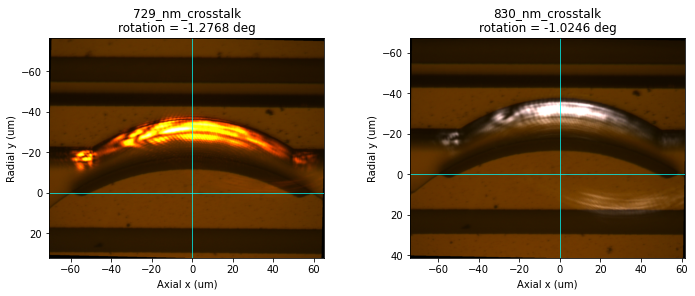

In [9]:
%matplotlib inline
preview_references(datasets, alignments)

## Process both wavelength datasets

Frames are processed one at a time. Caches include source files, dark calibration, alignment, thresholds, and exposure exclusions in their fingerprint.

In [10]:
missing = set(datasets) - set(alignments)
if missing:
    raise RuntimeError(f"Complete manual alignment for wavelengths {sorted(missing)} first.")
results = {}
for wl, dataset in datasets.items():
    results[wl] = process_dataset(dataset, alignments[wl], dark,
        min_signal=MIN_SIGNAL, max_rgb=MAX_RGB_CHANNEL, cache_dir=CACHE_DIR,
        excluded_exposures_ms=EXCLUDED_EXPOSURES_MS.get(wl, ()))

hdr_summary_all = pd.concat([r["summary"].assign(wavelength_nm=wl, dataset=r["dataset"]["name"])
                            for wl, r in results.items()], ignore_index=True)
saturation_all = pd.concat([r["saturation"].assign(wavelength_nm=wl)
                            for wl, r in results.items()], ignore_index=True)
hdr_summary_all.to_csv(OUTPUT_DIR / "hdr_peak_summary.csv", index=False)
saturation_all.to_csv(OUTPUT_DIR / "short_exposure_saturation.csv", index=False)
display(hdr_summary_all.groupby(["wavelength_nm", "dataset"]).agg(
    heights=("height_um", "size"), peaks_using_0p2_ms=("peak_uses_0p2_ms", "sum"),
    peak_rate_min=("peak_rate_counts_s", "min"), peak_rate_max=("peak_rate_counts_s", "max")))
if not saturation_all.empty:
    display(saturation_all.groupby("wavelength_nm")["all_channels_below_sat"].all())


729_nm_crosstalk: 1/21 heights
729_nm_crosstalk: 5/21 heights
729_nm_crosstalk: 10/21 heights
729_nm_crosstalk: 15/21 heights
729_nm_crosstalk: 20/21 heights
729_nm_crosstalk: 21/21 heights
830_nm_crosstalk: 1/21 heights
830_nm_crosstalk: 5/21 heights
830_nm_crosstalk: 10/21 heights
830_nm_crosstalk: 15/21 heights
830_nm_crosstalk: 20/21 heights
830_nm_crosstalk: 21/21 heights


,,heights,peaks_using_0p2_ms,peak_rate_min,peak_rate_max
wavelength_nm,dataset,,,,
729,729_nm_crosstalk,21,21,876676.0625,1502873.25
830,830_nm_crosstalk,21,20,563126.6250,2294386.50


wavelength_nm
729    False
830     True
Name: all_channels_below_sat, dtype: bool

## Peak HDR count rate versus height

Maximum over the full aligned 2-D HDR image at every height, independently for each wavelength. Rates are dark-corrected RGB counts divided by actual exposure seconds.

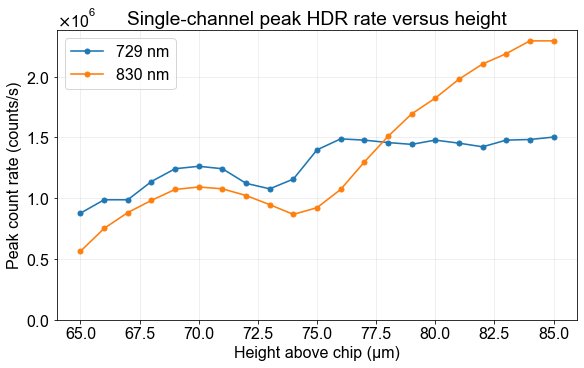

In [11]:
peak_count_rate_table = hdr_summary_all[["wavelength_nm", "height_um", "peak_rate_counts_s",
    "peak_x_um", "peak_y_um", "peak_requested_exposure_ms"]].copy()
with plt.rc_context({"font.family": "Arial", "font.size": 16}):
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    for wl, table in peak_count_rate_table.groupby("wavelength_nm", sort=True):
        ax.plot(table.height_um, table.peak_rate_counts_s, "o-", lw=1.6, ms=5, label=f"{wl} nm")
    ax.set(xlabel="Height above chip (µm)", ylabel="Peak count rate (counts/s)",
           title="Single-channel peak HDR rate versus height")
    ax.set_ylim(bottom=0)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.grid(alpha=.25)
    ax.legend()
    plt.show()
    plt.close(fig)


## HDR images, axial cuts, and exposure-selection maps

`HDR_SLICE_Y_UM` independently chooses each wavelength’s axial row. `None` follows the brightest pixel; a number selects the nearest physical y coordinate. This display setting does not alter the crosstalk/publication cuts.

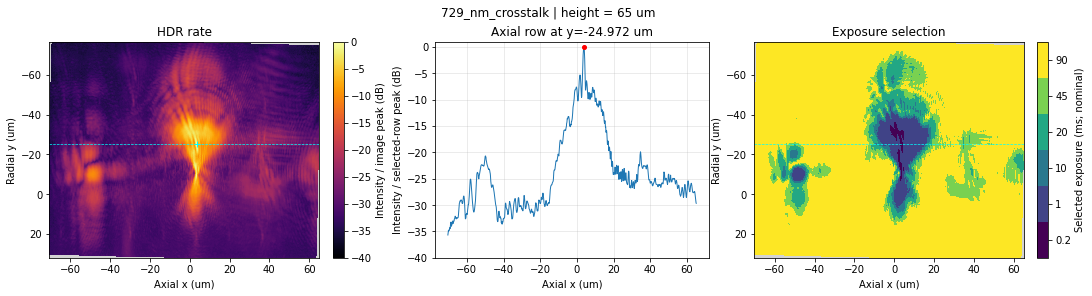

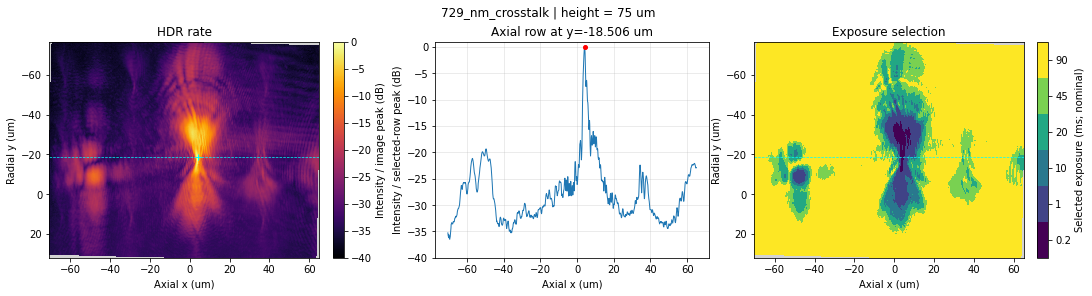

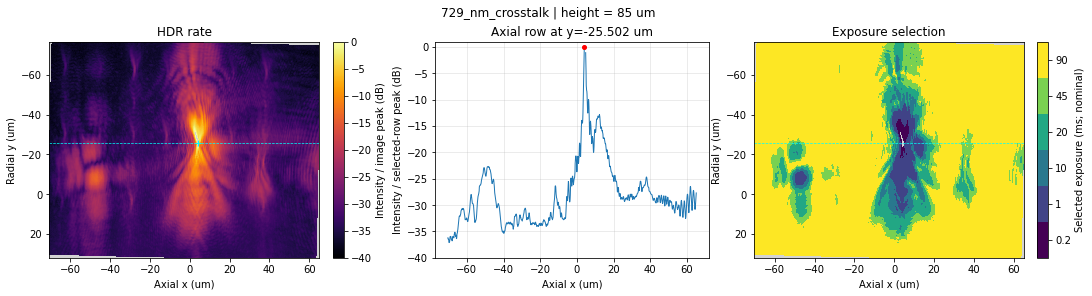

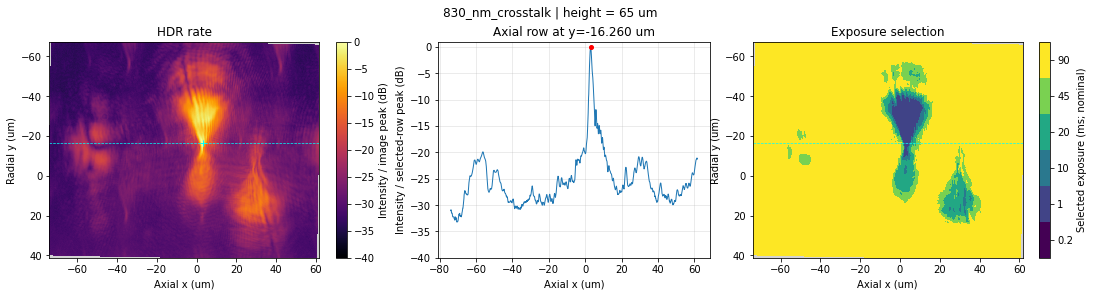

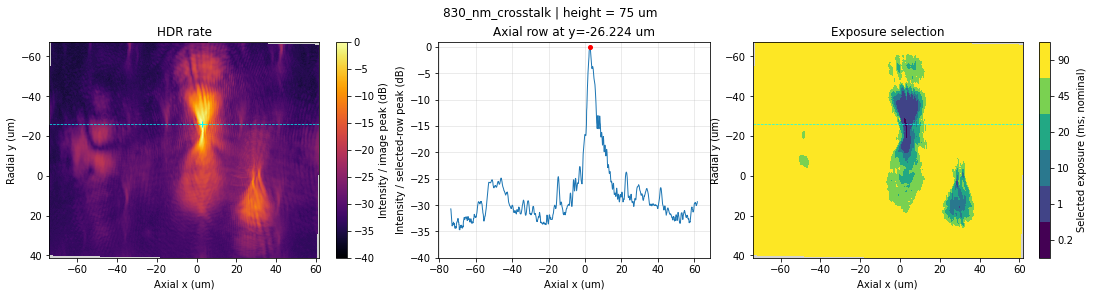

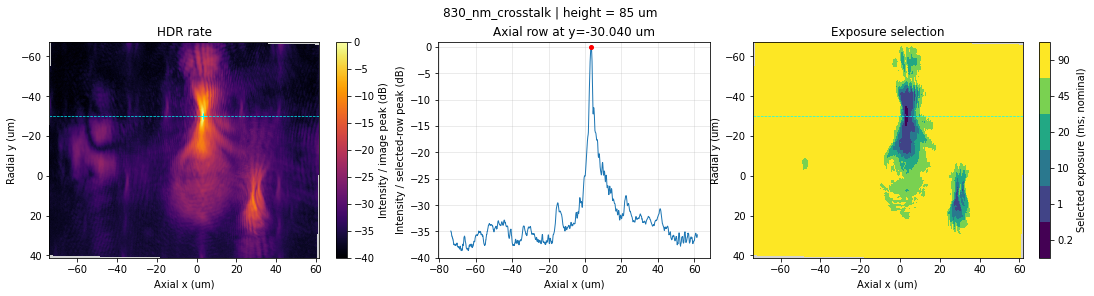

In [12]:
for wl, result in sorted(results.items()):
    plot_hdr(result, PLOT_HEIGHTS_UM, db_floor=DB_FLOOR, y_um=HDR_SLICE_Y_UM.get(wl))


## Verify longest-valid HDR exposure selection

Rebuild both longest-valid and maximum-rate exposure selections at the audit height and compare them. Far-field exposure diagnostics use one fixed ROI in each dataset. All nominal exposures are retained unless excluded in settings.

729 nm: longest-valid HDR verified


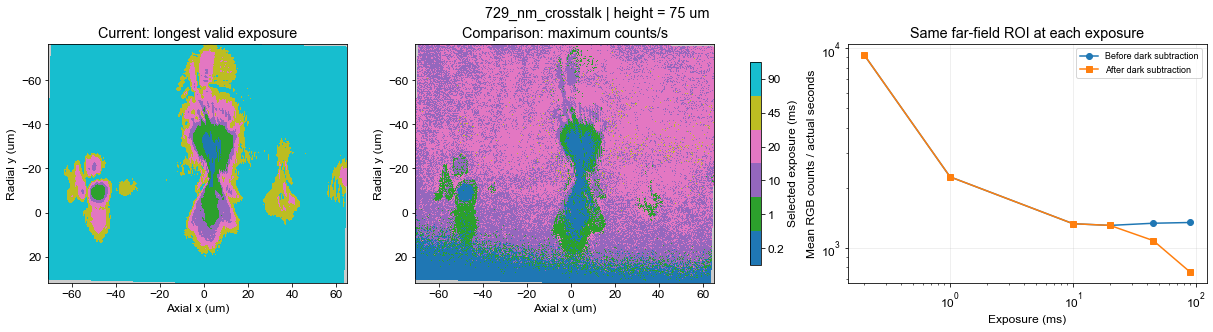

strategy,Comparison: maximum rate,Current: longest valid
exposure_ms,,
0.2,15.00,0.00
1.0,5.58,0.00
10.0,36.61,0.00
20.0,42.60,0.72
45.0,0.21,1.22
90.0,0.00,98.06


,point,x_um,y_um,exposure_ms,actual_exposure_ms,raw_counts,dark_counts,corrected_counts,rate_counts_s,max_channel,valid,selected_current
0,2D peak,4.108,-18.506,0.2,0.2,279.0,0.000,279.000,1397672.125,217,True,True
1,selected-row peak,4.108,-18.506,0.2,0.2,279.0,0.000,279.000,1397672.125,217,True,True
2,"selected row, peak + 5 um",9.090,-18.506,0.2,0.2,3.0,0.000,3.000,15028.732,3,False,False
3,"selected row, peak + 25 um",29.124,-18.506,0.2,0.2,0.0,0.000,0.000,0.000,0,False,False
4,2D peak,4.108,-18.506,1.0,1.0,577.0,0.000,577.000,577129.750,255,False,False
5,selected-row peak,4.108,-18.506,1.0,1.0,577.0,0.000,577.000,577129.750,255,False,False
6,"selected row, peak + 5 um",9.090,-18.506,1.0,1.0,23.0,0.000,23.000,23005.174,19,True,False
7,"selected row, peak + 25 um",29.124,-18.506,1.0,1.0,0.0,0.000,0.000,0.000,0,False,False
8,2D peak,4.108,-18.506,10.0,10.0,765.0,0.000,765.000,76500.000,255,False,False
9,selected-row peak,4.108,-18.506,10.0,10.0,765.0,0.000,765.000,76500.000,255,False,False


,exposure_ms,actual_exposure_ms,dark_counts,raw_mean_counts,raw_mean_rate_counts_s,corrected_mean_rate_counts_s,valid_roi_percent
0,0.2,0.2,0.000,1.850,9268.667,9268.667,14.995
1,1.0,1.0,0.000,2.270,2270.425,2270.425,18.808
2,10.0,10.0,0.000,13.234,1323.436,1323.436,95.262
3,20.0,20.0,0.000,25.949,1297.470,1297.468,100.000
4,45.0,45.0,10.848,59.868,1330.398,1089.331,99.282
5,90.0,90.0,52.636,120.759,1341.763,756.914,98.064


830 nm: longest-valid HDR verified


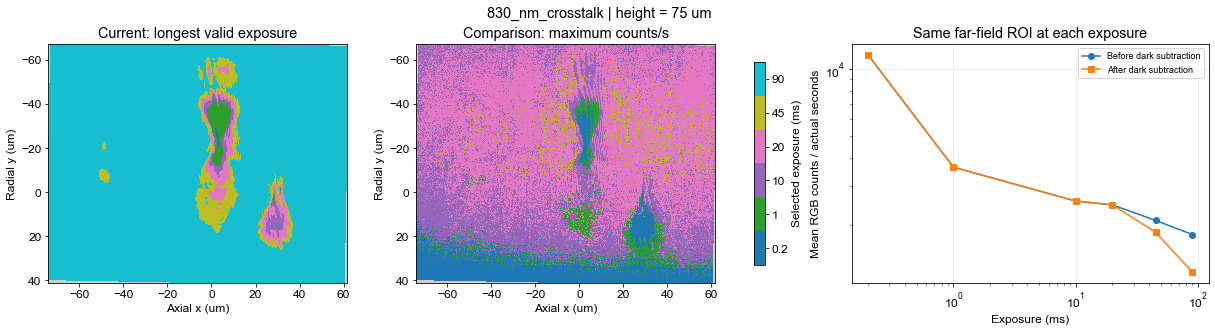

strategy,Comparison: maximum rate,Current: longest valid
exposure_ms,,
0.2,18.15,0.00
1.0,6.30,0.04
10.0,35.34,1.26
20.0,39.46,2.17
45.0,0.75,1.78
90.0,0.00,94.74


,point,x_um,y_um,exposure_ms,actual_exposure_ms,raw_counts,dark_counts,corrected_counts,rate_counts_s,max_channel,valid,selected_current
0,2D peak,2.690,-26.224,0.2,0.2,184.0,0.000,184.000,921762.250,65,True,True
1,selected-row peak,2.690,-26.224,0.2,0.2,184.0,0.000,184.000,921762.250,65,True,True
2,"selected row, peak + 5 um",7.672,-26.224,0.2,0.2,3.0,0.000,3.000,15028.732,1,False,False
3,"selected row, peak + 25 um",27.706,-26.224,0.2,0.2,0.0,0.000,0.000,0.000,0,False,False
4,2D peak,2.690,-26.224,1.0,1.0,765.0,0.000,765.000,765172.062,255,False,False
5,selected-row peak,2.690,-26.224,1.0,1.0,765.0,0.000,765.000,765172.062,255,False,False
6,"selected row, peak + 5 um",7.672,-26.224,1.0,1.0,19.0,0.000,19.000,19004.273,7,True,False
7,"selected row, peak + 25 um",27.706,-26.224,1.0,1.0,0.0,0.000,0.000,0.000,0,False,False
8,2D peak,2.690,-26.224,10.0,10.0,765.0,0.000,765.000,76500.000,255,False,False
9,selected-row peak,2.690,-26.224,10.0,10.0,765.0,0.000,765.000,76500.000,255,False,False


,exposure_ms,actual_exposure_ms,dark_counts,raw_mean_counts,raw_mean_rate_counts_s,corrected_mean_rate_counts_s,valid_roi_percent
0,0.2,0.2,0.000,2.308,11564.581,11564.581,18.319
1,1.0,1.0,0.000,3.639,3639.386,3639.386,24.235
2,10.0,10.0,0.000,25.692,2569.212,2569.212,93.205
3,20.0,20.0,0.000,49.370,2468.514,2468.513,98.695
4,45.0,45.0,10.848,94.750,2105.548,1864.481,96.525
5,90.0,90.0,52.636,163.848,1820.534,1235.685,94.741


In [13]:
hdr_exposure_audits = {}
for wl, result in sorted(results.items()):
    audit = audit_hdr_exposure_selection(result, dark, HDR_AUDIT_HEIGHT_UM,
                                         CROSSTALK_Y_UM.get(wl))
    hdr_exposure_audits[wl] = audit
    print(f"{wl} nm: longest-valid HDR verified")
    plot_hdr_exposure_audit(audit)
    display(audit["usage"].pivot(index="exposure_ms", columns="strategy", values="far_field_percent").round(2))
    display(audit["pixels"].round(3))
    display(audit["background"].round(3))


## Single-channel crosstalk at ±5 µm versus height

At each height and selected radial row, locate that row’s axial peak and sample −5, 0, and +5 µm from it using nearest measured pixels. Normalize to that same row’s peak. Requested and sampled coordinates are recorded. The two offset curves belong to one driven beam per wavelength.

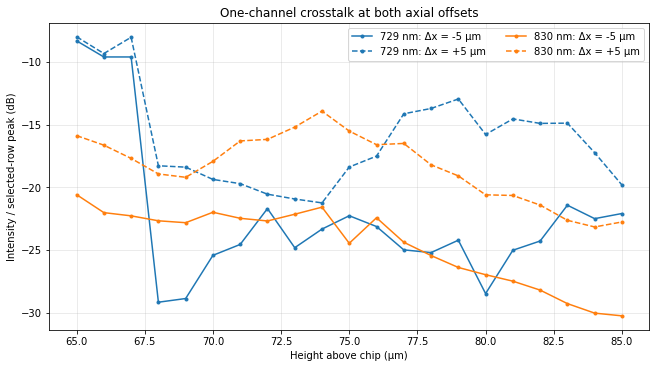

,wavelength_nm,driven_channel,dataset,height_um,offset_um,peak_x_um,requested_y_um,sample_y_um,target_x_um,sample_x_um,actual_offset_um,central_rate_counts_s,sample_rate_counts_s,crosstalk_db
0,729,0,729_nm_crosstalk,65.0,-5.0,3.790446,None,-24.971518,-1.209554,-1.191554,-4.982,8.766761e+05,1.290290e+05,-8.321518
1,729,0,729_nm_crosstalk,65.0,0.0,3.790446,None,-24.971518,3.790446,3.790446,0.000,8.766761e+05,8.766761e+05,0.000000
2,729,0,729_nm_crosstalk,65.0,5.0,3.790446,None,-24.971518,8.790446,8.772446,4.982,8.766761e+05,1.390313e+05,-7.997267
3,729,0,729_nm_crosstalk,66.0,-5.0,4.108446,None,-24.865518,-0.891554,-0.873554,-4.982,9.868868e+05,1.080243e+05,-9.607459
4,729,0,729_nm_crosstalk,66.0,0.0,4.108446,None,-24.865518,4.108446,4.108446,0.000,9.868868e+05,9.868868e+05,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,830,0,830_nm_crosstalk,84.0,0.0,3.325750,None,-29.615643,3.325750,3.325750,0.000,2.294386e+06,2.294386e+06,0.000000
122,830,0,830_nm_crosstalk,84.0,5.0,3.325750,None,-29.615643,8.325750,8.307750,4.982,2.294386e+06,1.109227e+04,-23.156463
123,830,0,830_nm_crosstalk,85.0,-5.0,3.325750,None,-30.039643,-1.674250,-1.656250,-4.982,2.294386e+06,2.170707e+03,-30.240655
124,830,0,830_nm_crosstalk,85.0,0.0,3.325750,None,-30.039643,3.325750,3.325750,0.000,2.294386e+06,2.294386e+06,0.000000


In [14]:
spatial_crosstalk = single_channel_crosstalk(results,
    offset_um=CROSSTALK_OFFSET_UM, y_um=CROSSTALK_Y_UM)
spatial_crosstalk.to_csv(OUTPUT_DIR / "single_channel_crosstalk_all_heights.csv", index=False)
plot_single_channel_scan(spatial_crosstalk)
display(spatial_crosstalk)


## Sampled-position matrix at the selected height

Each column is a separate wavelength’s single driven channel. Rows are axial offsets from its own peak: −5 µm, center, and +5 µm. The center is 0 dB when valid. These spatial samples do not imply that additional driven channels or a wavelength-to-wavelength response were measured.

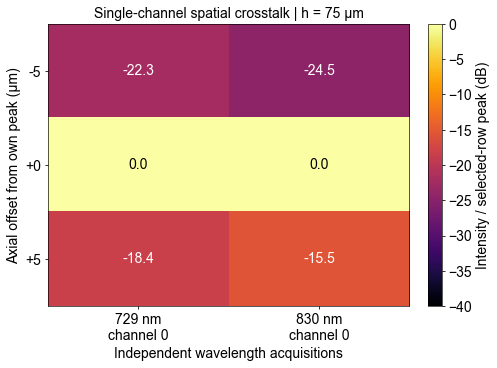

wavelength_nm,729,830
offset_um,,
-5.0,-22.263273,-24.455736
0.0,0.000000,0.000000
5.0,-18.379093,-15.513192


In [15]:
plot_single_channel_matrix(spatial_crosstalk, MATRIX_HEIGHT_UM, db_floor=DB_FLOOR)
selected = spatial_crosstalk[np.isclose(spatial_crosstalk.height_um, MATRIX_HEIGHT_UM,
                                       rtol=0, atol=1e-4)]
display(selected.pivot(index="offset_um", columns="wavelength_nm", values="crosstalk_db"))


## Sampled-position matrices at all common heights

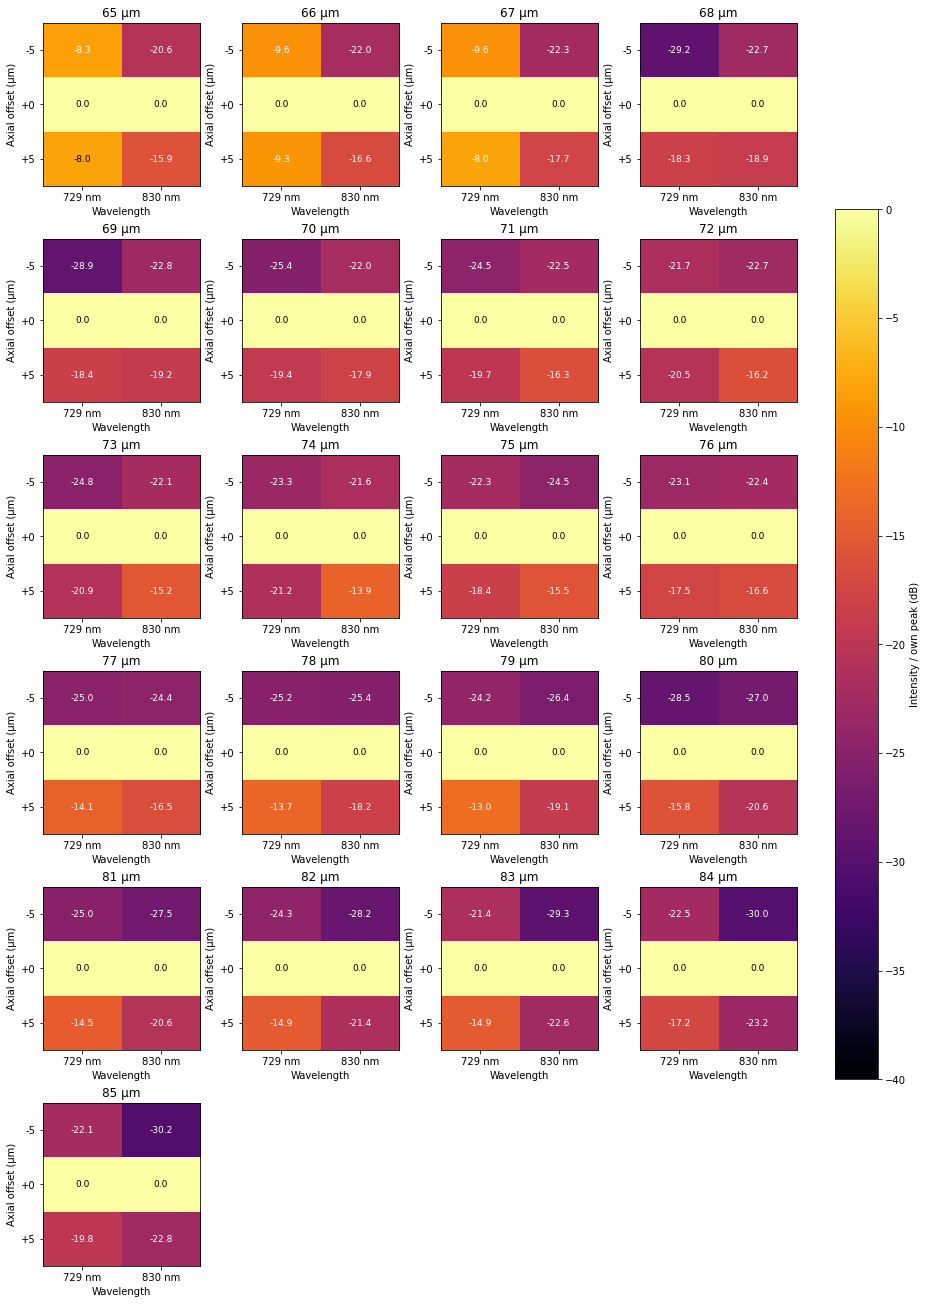

In [16]:
plot_single_channel_matrix_grid(spatial_crosstalk, db_floor=DB_FLOOR)

## Publication reference windows

Find each wavelength’s brightest valid HDR pixel at the reference height (75 µm by default). Its radial coordinate sets Δy = 0. For nominal heights 65–85 µm and radial offsets −5 to +5 µm in 1 µm steps, select the nearest measured height and row. On each selected row, track the axial maximum and sample both −5 and +5 µm from it.

Crosstalk is **10 log₁₀(neighbor rate / peak rate)** on the same height/radial slice. No interpolation or smoothing is applied. This gives **two spatial-offset maps per wavelength, four maps total**.

In [17]:
publication_scan = analyze_reference_windows(
    results, PUBLICATION_OFFSETS_UM,
    reference_height_um=PUBLICATION_REFERENCE_HEIGHT_UM,
    height_half_range_um=PUBLICATION_HEIGHT_HALF_RANGE_UM,
    radial_half_range_um=PUBLICATION_RADIAL_HALF_RANGE_UM,
    radial_step_um=PUBLICATION_RADIAL_STEP_UM,
    height_step_um=PUBLICATION_HEIGHT_STEP_UM,
    peak_search_half_width_um=PUBLICATION_PEAK_SEARCH_HALF_WIDTH_UM,
)
publication_scan["settings"].update(
    driven_channels_per_wavelength=1,
    dark_calibration_path=str(DARK_PATH),
    dark_calibration_sha256=hashlib.sha256(DARK_PATH.read_bytes()).hexdigest(),
    uncertainty_note="Point estimates only: one signal frame per exposure/height; dark calibration stores spatial means, not variances.",
)
publication_quality = export_reference_windows(
    publication_scan, results, PUBLICATION_DIR, PUBLICATION_DB_LIMITS)
display(publication_scan["anchors"])
display(publication_scan["baseline"])
display(publication_quality)


,wavelength_nm,dataset,reference_height_um,peak_x_um,peak_y_um,reference_peak_counts_s,reference_exposure_ms,reference_nominal_exposure_ms,native_radial_step_um,radial_samples,radial_sample_step_um,height_sample_step_um
0,729,729_nm_crosstalk,75.0,4.108446,-18.505518,1397672.125,0.199618,0.2,0.106,11,1.0,1.0
1,830,830_nm_crosstalk,75.0,2.689750,-26.223643,921762.250,0.199618,0.2,0.106,11,1.0,1.0


,wavelength_nm,offset_um,height_um,peak_x_um,peak_y_um,target_x_um,sample_x_um,actual_offset_um,central_rate_counts_s,neighbor_rate_counts_s,crosstalk_linear,crosstalk_db
0,729,-5.0,75.0,4.108446,-18.505518,-0.891554,-0.873554,-4.982,1397672.125,8299.999023,0.005938,-22.263273
1,729,5.0,75.0,4.108446,-18.505518,9.108446,9.090446,4.982,1397672.125,20300.000000,0.014524,-18.379093
2,830,-5.0,75.0,2.689750,-26.223643,-2.310250,-2.292250,-4.982,921762.250,3304.039795,0.003584,-24.455736
3,830,5.0,75.0,2.689750,-26.223643,7.689750,7.671750,4.982,921762.250,25900.000000,0.028098,-15.513192


,wavelength_nm,offset_um,valid_samples,total_samples,valid_fraction,min_db,max_db,max_abs_peak_shift_um,samples_below_color_min,samples_above_color_max
0,729,-5.0,231,231,1.0,-29.450383,-1.856366,2.438,0,0
1,729,5.0,231,231,1.0,-21.978893,-2.603707,2.438,0,0
2,830,-5.0,231,231,1.0,-30.114536,-0.059739,3.604,0,0
3,830,5.0,231,231,1.0,-23.107902,-0.170780,3.604,0,0


## Publication profiles and height–radial maps

One reference axial profile per wavelength, each marked at both offsets. The 2×2 map layout has wavelengths in rows and −5/+5 µm offsets in columns. White contours mark −20 dB; circles mark the reference height/radial coordinate.

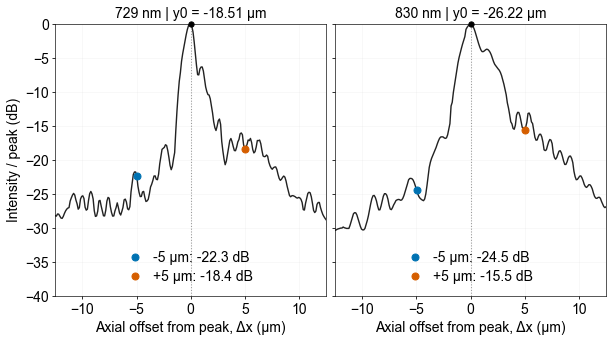

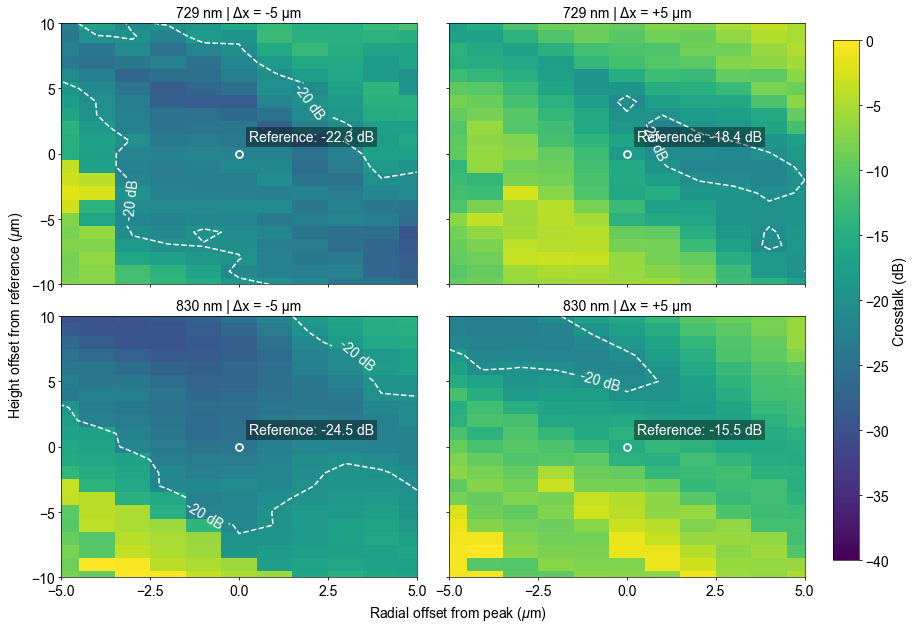

In [18]:
plot_reference_axial_profiles(publication_scan, db_limits=PUBLICATION_DB_LIMITS,
                              font_family="Arial", font_size=14)
plot_height_radial_maps(publication_scan, color_limits_db=PUBLICATION_DB_LIMITS,
                       contour_db=-20.0, font_family="Arial", font_size=14)


## Analysis diagnostics

Peak-tracking maps show movement of the axial maximum. Exposure-consistency plots compare retained, unsaturated count rates at each wavelength’s reference peak. Diagnostics do not modify the HDR or peak-following calculation.

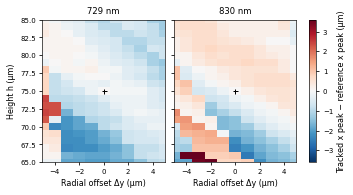

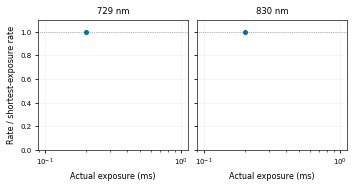

,wavelength_nm,requested_exposure_ms,actual_exposure_ms,rate_counts_s,rate_relative_to_shortest,passes_thresholds,selected_at_peak
0,729,0.2,0.199618,1.397672e+06,1.000000,True,True
1,729,1.0,0.999775,5.771298e+05,0.412922,False,False
2,729,10.0,10.000000,7.650000e+04,0.054734,False,False
3,729,20.0,20.000000,3.825000e+04,0.027367,False,False
4,729,45.0,45.000000,1.675893e+04,0.011991,False,False
5,729,90.0,90.000000,7.915151e+03,0.005663,False,False
6,830,0.2,0.199618,9.217623e+05,1.000000,True,True
7,830,1.0,0.999775,7.651721e+05,0.830119,False,False
8,830,10.0,10.000000,7.650000e+04,0.082993,False,False
9,830,20.0,20.000000,3.825000e+04,0.041497,False,False


Data tables, arrays, and settings saved to: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/cross_talk_results_og_single_channel/publication_75um


In [19]:
plot_peak_tracking_diagnostic(publication_scan)
publication_exposure_check = reference_exposure_diagnostic(
    results, PUBLICATION_REFERENCE_HEIGHT_UM, PUBLICATION_DIR)
display(publication_exposure_check[["wavelength_nm", "requested_exposure_ms", "actual_exposure_ms",
    "rate_counts_s", "rate_relative_to_shortest", "passes_thresholds", "selected_at_peak"]])
print(f"Data tables, arrays, and settings saved to: {PUBLICATION_DIR}")


## Optional figure export

Uncomment the next cell after checking the figures. Export the sampled-position matrix, reference profiles, and four crosstalk maps as PDF/PNG/SVG. Figure files are written only by this optional cell; analysis tables and arrays are saved by the processing/publication cells above.

In [20]:
# FIGURE_EXPORT_DIR = OUTPUT_DIR / "figures"
# exported_paths = export_single_channel_figures(
#     spatial_crosstalk, publication_scan, FIGURE_EXPORT_DIR,
#     matrix_height_um=MATRIX_HEIGHT_UM, db_floor=DB_FLOOR,
#     color_limits_db=PUBLICATION_DB_LIMITS, formats=("pdf", "png"), dpi=600,
# )
# for path in exported_paths:
#     print(path)
